# Results Registry

Keep the preprocessing registry minimal: baseline, model size, artifact type, adaptive flag, and file path. Everything else can be derived later during analysis.


In [1]:
from __future__ import annotations

from collections import Counter
from dataclasses import dataclass
from pathlib import Path
import json
from typing import Any

def find_repo_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "evals").exists():
            return candidate
    raise FileNotFoundError(f"Could not find repository root from {start}")


REPO_ROOT = find_repo_root(Path.cwd())
DATA_ROOT = REPO_ROOT / "analysis" / "data"
assert DATA_ROOT.exists(), f"Missing analysis data directory: {DATA_ROOT}"

def repo_relative_path(path: str | Path | None) -> str | None:
    if path is None:
        return None
    path_obj = Path(path)
    try:
        return path_obj.resolve().relative_to(REPO_ROOT.resolve()).as_posix()
    except ValueError:
        return path_obj.name


def repo_relative_paths(paths: dict[str, str | Path | None]) -> dict[str, str | None]:
    return {name: repo_relative_path(path) for name, path in paths.items()}


RESULTS = "results"
ADAPTIVE_POLICY = "adaptive_policy"
ADAPTIVE_BUDGET_POLICY = "adaptive_budget_policy"


@dataclass(frozen=True)
class DataPoint:
    baseline: str
    model_size: int
    type: str
    adaptive: bool
    path: str


def add_datapoint(
    registry: list[DataPoint],
    *,
    baseline: str,
    model_size: int,
    type: str,
    adaptive: bool,
    filename: str,
) -> None:
    registry.append(
        DataPoint(
            baseline=baseline,
            model_size=model_size,
            type=type,
            adaptive=adaptive,
            path=str(DATA_ROOT / filename),
        )
    )


def read_jsonl_records(path: str | Path) -> list[dict[str, Any]]:
    path = Path(path)
    with path.open() as handle:
        return [json.loads(line) for line in handle if line.strip()]


def read_first_jsonl_record(path: str | Path) -> dict[str, Any]:
    path = Path(path)
    with path.open() as handle:
        for line in handle:
            if line.strip():
                return json.loads(line)
    raise ValueError(f"No JSONL rows found in {path}")

datapoints: list[DataPoint] = []

for baseline in ["base-repair", "cot-repair", "intervenor", "tracecoder"]:
    for model_size, filename in [
        (4, f"final-{baseline}-4b.jsonl"),
        (9, f"final-{baseline}-9b.jsonl"),
        (35, f"final-{baseline}-35b.jsonl"),
    ]:
        add_datapoint(
            datapoints,
            baseline=baseline,
            model_size=model_size,
            type=RESULTS,
            adaptive=False,
            filename=filename,
        )

for model_size, filename in [
    (4, "final-lambda-rlm-4B.jsonl"),
    (9, "final-lambda-rlm-9B.jsonl"),
    (35, "final-lambda-rlm-35B2.jsonl"),
]:
    add_datapoint(
        datapoints,
        baseline="lambda-rlm",
        model_size=model_size,
        type=RESULTS,
        adaptive=False,
        filename=filename,
    )

for baseline in ["base-repair", "cot-repair", "intervenor", "lambda-rlm", "tracecoder"]:
    stem = f"final-{baseline}-adaptive-repair-35b"
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=35,
        type=RESULTS,
        adaptive=True,
        filename=f"{stem}.jsonl",
    )
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=35,
        type=ADAPTIVE_POLICY,
        adaptive=True,
        filename=f"{stem}.adaptive_policy.jsonl",
    )
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=35,
        type=ADAPTIVE_BUDGET_POLICY,
        adaptive=True,
        filename=f"{stem}.adaptive_budget_policy.jsonl",
    )

for baseline, stem in [
    ("base-repair", "final-base-repair-adaptive-9b"),
    ("cot-repair", "final-cot-repair-adaptive-9b"),
    ("intervenor", "final-intervenor-adaptive-repair-9b"),
    ("lambda-rlm", "final-lambda-rlm-adaptive-repair-9b"),
    ("tracecoder", "final-tracecoder-adaptive-repair-9b"),
]:
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=9,
        type=RESULTS,
        adaptive=True,
        filename=f"{stem}.jsonl",
    )
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=9,
        type=ADAPTIVE_POLICY,
        adaptive=True,
        filename=f"{stem}.adaptive_policy.jsonl",
    )
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=9,
        type=ADAPTIVE_BUDGET_POLICY,
        adaptive=True,
        filename=f"{stem}.adaptive_budget_policy.jsonl",
    )

for baseline in ["base-repair", "cot-repair", "intervenor", "lambda-rlm", "tracecoder"]:
    stem = f"qwen35-4b-fd-{baseline}-layered-adaptive-llm"
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=4,
        type=RESULTS,
        adaptive=True,
        filename=f"{stem}.jsonl",
    )
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=4,
        type=ADAPTIVE_POLICY,
        adaptive=True,
        filename=f"{stem}.adaptive_policy.jsonl",
    )
    add_datapoint(
        datapoints,
        baseline=baseline,
        model_size=4,
        type=ADAPTIVE_BUDGET_POLICY,
        adaptive=True,
        filename=f"{stem}.adaptive_budget_policy.jsonl",
    )

IGNORED_TOP_LEVEL_JSONL = {
    "ablation-fixed-final.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base2.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base3.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base4.jsonl": "Ablation artifact outside the analysis registry",
    "final-lambda-rlm-35B.jsonl": "Superseded by final-lambda-rlm-35B2.jsonl",
    "ablation-gemma-4-all-failed-final.adaptive_budget_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed-final.adaptive_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed-final.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed.adaptive_budget_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed.adaptive_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-fixed.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-glm.jsonl": "Ablation artifact outside the analysis registry",
}

results_datapoints = [dp for dp in datapoints if dp.type == RESULTS]
policy_datapoints = [dp for dp in datapoints if dp.type == ADAPTIVE_POLICY]
budget_policy_datapoints = [dp for dp in datapoints if dp.type == ADAPTIVE_BUDGET_POLICY]

def load_records(datapoint: DataPoint) -> list[dict[str, Any]]:
    return read_jsonl_records(datapoint.path)


def load_dataframe(datapoint: DataPoint):
    try:
        import pandas as pd
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            "Pandas is optional here. Install it in the notebook kernel if you want DataFrames, "
            "for example with `uv pip install pandas`."
        ) from exc

    df = pd.read_json(datapoint.path, lines=True)
    return df.assign(
        baseline=datapoint.baseline,
        model_size=datapoint.model_size,
        type=datapoint.type,
        adaptive=datapoint.adaptive,
    )


datapoints_by_key = {
    (dp.baseline, dp.model_size, dp.type, dp.adaptive): dp for dp in datapoints
}
REQUIRED_FIELDS = {
    RESULTS: {"case_id", "success"},
    ADAPTIVE_POLICY: {"case_id", "selected_action"},
    ADAPTIVE_BUDGET_POLICY: {"case_id", "selected_family", "tier_index_before"},
}

actual_top_level_files = sorted(path.name for path in DATA_ROOT.glob("*.jsonl"))
mapped_files = sorted(Path(dp.path).name for dp in datapoints)
accounted_for_files = set(mapped_files) | set(IGNORED_TOP_LEVEL_JSONL)

assert set(actual_top_level_files) == accounted_for_files, (
    "Top-level JSONL accounting mismatch. "
    f"Missing={sorted(set(actual_top_level_files) - accounted_for_files)}; "
    f"Extra={sorted(accounted_for_files - set(actual_top_level_files))}"
)
assert IGNORED_TOP_LEVEL_JSONL == {
    "ablation-fixed-final.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base2.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base3.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-intervenor-order-base4.jsonl": "Ablation artifact outside the analysis registry",
    "final-lambda-rlm-35B.jsonl": "Superseded by final-lambda-rlm-35B2.jsonl",
    "ablation-gemma-4-all-failed-final.adaptive_budget_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed-final.adaptive_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed-final.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed.adaptive_budget_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed.adaptive_policy.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-4-all-failed.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-gemma-fixed.jsonl": "Ablation artifact outside the analysis registry",
    "ablation-glm.jsonl": "Ablation artifact outside the analysis registry",
}

for datapoint in datapoints:
    first_record = read_first_jsonl_record(datapoint.path)
    missing_fields = sorted(REQUIRED_FIELDS[datapoint.type] - set(first_record))
    assert not missing_fields, (
        f"{Path(datapoint.path).name} is missing required fields for {datapoint.type}: {missing_fields}"
    )

summary = {
    "total_datapoints": len(datapoints),
    "type_counts": dict(Counter(dp.type for dp in datapoints)),
    "adaptive_counts": dict(Counter(dp.adaptive for dp in datapoints)),
    "baseline_counts": dict(Counter(dp.baseline for dp in datapoints)),
}

print("Validated minimal datapoint registry.")
summary


Validated minimal datapoint registry.


{'total_datapoints': 60,
 'type_counts': {'results': 30,
  'adaptive_policy': 15,
  'adaptive_budget_policy': 15},
 'adaptive_counts': {False: 15, True: 45},
 'baseline_counts': {'base-repair': 12,
  'cot-repair': 12,
  'intervenor': 12,
  'tracecoder': 12,
  'lambda-rlm': 12}}

In [2]:
try:
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This normalization cell uses pandas. Install it in the notebook kernel, "
        "for example with `uv pip install pandas`."
    ) from exc

results_frames = []

for datapoint in results_datapoints:
    frame = pd.DataFrame.from_records(read_jsonl_records(datapoint.path))
    frame = frame.assign(
        baseline=datapoint.baseline,
        model_size=datapoint.model_size,
        adaptive=datapoint.adaptive,
        source_path=repo_relative_path(datapoint.path),
    )
    results_frames.append(frame)

results_table = pd.concat(results_frames, ignore_index=True)
results_table = results_table[
    [
        "baseline",
        "model_size",
        "adaptive",
        "case_id",
        "success",
        "condition",
        "difficulty",
        "attempt",
        "source_path",
    ]
].sort_values(
    ["baseline", "model_size", "adaptive", "case_id", "attempt"],
    ignore_index=True,
)

results_table.head()


,baseline,model_size,adaptive,case_id,success,condition,difficulty,attempt,source_path
0,base-repair,4,False,async_aiter_cleanup_not_run_hard,False,base_repair,hard,1,analysis/data/final-base-repair-4b.jsonl
1,base-repair,4,False,async_aiter_cleanup_not_run_hard,False,base_repair,hard,2,analysis/data/final-base-repair-4b.jsonl
2,base-repair,4,False,async_cancel_swallowed_medium,True,base_repair,medium,1,analysis/data/final-base-repair-4b.jsonl
3,base-repair,4,False,async_cancelled_error_swallowed_medium,True,base_repair,medium,1,analysis/data/final-base-repair-4b.jsonl
4,base-repair,4,False,async_condition_notify_before_wait_medium,False,base_repair,medium,1,analysis/data/final-base-repair-4b.jsonl


In [3]:
try:
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This table cell uses pandas. Install it in the notebook kernel, "
        "for example with `uv pip install pandas`."
    ) from exc

BASELINE_DISPLAY = {
    "base-repair": "Base Repair",
    "cot-repair": "CoT Repair",
    "intervenor": "Intervenor",
    "lambda-rlm": "Lambda-RLM",
    "tracecoder": "TraceCoder",
}

BENCHMARK_DISPLAY = {
    "condefects": "ConDefects (Solve@1 / Solve@2 / Avg total token per task)",
    "debugbench": "DebugBench (Solve@1 / Solve@2 / Avg total token per task)",
    "humanevalpack": "HumanEvalPack (Solve@1 / Solve@2 / Avg total token per task)",
    "hand_crafted": "Hand-crafted (Solve@1 / Solve@2 / Avg total token per task)",
}

BASELINE_ORDER = list(BASELINE_DISPLAY)
BASELINE_ORDER_INDEX = {
    baseline: index for index, baseline in enumerate(BASELINE_ORDER)
}
MODEL_ORDER = sorted({dp.model_size for dp in results_datapoints if not dp.adaptive})
MODEL_ORDER_INDEX = {
    model_size: index for index, model_size in enumerate(MODEL_ORDER)
}


def model_label(model_size: int) -> str:
    return f"Qwen {model_size}B"


def baseline_label(baseline: str) -> str:
    return BASELINE_DISPLAY[baseline]


def format_solve_rate(solved: int, task_count: int) -> str:
    if task_count == 0:
        return "-/- (-)"
    return f"{solved}/{task_count} ({solved / task_count:.1%})"


def format_metric_cell(group: pd.DataFrame) -> str:
    if group.empty:
        return "- / - / -"
    row = group.iloc[0]
    task_count = int(row["task_count"])
    solved_at_1 = int(row["solved_at_1"])
    solved_at_2 = int(row["solved_at_2"])
    return (
        f"{format_solve_rate(solved_at_1, task_count)} / "
        f"{format_solve_rate(solved_at_2, task_count)} / "
        f"{row['avg_total_tokens_per_task']:,.0f}"
    )


metric_rows = []

static_results_datapoints = [dp for dp in results_datapoints if not dp.adaptive]

for datapoint in static_results_datapoints:
    for row in read_jsonl_records(datapoint.path):
        attempt_metadata = row.get("attempt_metadata") or {}
        metric_rows.append(
            {
                "baseline": datapoint.baseline,
                "model_size": datapoint.model_size,
                "bug_source": row.get("bug_source") or "hand_crafted",
                "case_id": row["case_id"],
                "attempt": int(row.get("attempt") or 0),
                "success": bool(row.get("success")),
                "tokens_total": float(attempt_metadata.get("tokens_total") or 0),
            }
        )

metrics_df = pd.DataFrame.from_records(metric_rows)
metrics_df["success_at_1"] = metrics_df["success"] & (metrics_df["attempt"] == 1)
metrics_df["success_at_2"] = metrics_df["success"] & (metrics_df["attempt"] <= 2)

task_summary = (
    metrics_df.groupby(
        ["baseline", "model_size", "bug_source", "case_id"],
        as_index=False,
        dropna=False,
    )
    .agg(
        solve_at_1=("success_at_1", "max"),
        solve_at_2=("success_at_2", "max"),
        total_tokens_per_task=("tokens_total", "sum"),
    )
)

benchmark_summary = (
    task_summary.groupby(["baseline", "model_size", "bug_source"], as_index=False)
    .agg(
        solved_at_1=("solve_at_1", "sum"),
        solved_at_2=("solve_at_2", "sum"),
        task_count=("case_id", "size"),
        avg_total_tokens_per_task=("total_tokens_per_task", "mean"),
    )
)

row_index = (
    benchmark_summary[["baseline", "model_size"]]
    .drop_duplicates()
    .assign(
        model_order=lambda frame: frame["model_size"].map(MODEL_ORDER_INDEX),
        baseline_order=lambda frame: frame["baseline"].map(BASELINE_ORDER_INDEX),
    )
    .sort_values(["model_order", "baseline_order"], ignore_index=True)
    [["baseline", "model_size"]]
)

table_rows = []

for row in row_index.itertuples(index=False):
    table_row = {
        "Model": model_label(row.model_size),
        "Baseline": baseline_label(row.baseline),
    }
    for bug_source, column_name in BENCHMARK_DISPLAY.items():
        group = benchmark_summary.loc[
            (benchmark_summary["baseline"] == row.baseline)
            & (benchmark_summary["model_size"] == row.model_size)
            & (benchmark_summary["bug_source"] == bug_source)
        ]
        table_row[column_name] = format_metric_cell(group)
    table_rows.append(table_row)

benchmark_table = pd.DataFrame(
    table_rows,
    columns=["Model", "Baseline", *BENCHMARK_DISPLAY.values()],
)
benchmark_table


,Model,Baseline,ConDefects (Solve@1 / Solve@2 / Avg total token per task),DebugBench (Solve@1 / Solve@2 / Avg total token per task),HumanEvalPack (Solve@1 / Solve@2 / Avg total token per task),Hand-crafted (Solve@1 / Solve@2 / Avg total token per task)
0,Qwen 4B,Base Repair,"316/1267 (24.9%) / 370/1267 (29.2%) / 14,826","124/328 (37.8%) / 172/328 (52.4%) / 2,888","115/164 (70.1%) / 127/164 (77.4%) / 2,106","49/69 (71.0%) / 53/69 (76.8%) / 2,119"
1,Qwen 4B,CoT Repair,"409/1267 (32.3%) / 483/1267 (38.1%) / 24,551","121/328 (36.9%) / 176/328 (53.7%) / 6,594","121/164 (73.8%) / 143/164 (87.2%) / 4,543","60/69 (87.0%) / 62/69 (89.9%) / 3,951"
2,Qwen 4B,Intervenor,"643/1267 (50.7%) / 719/1267 (56.7%) / 19,640","247/328 (75.3%) / 267/328 (81.4%) / 8,627","157/164 (95.7%) / 162/164 (98.8%) / 2,987","63/69 (91.3%) / 63/69 (91.3%) / 3,387"
3,Qwen 4B,Lambda-RLM,"606/1267 (47.8%) / 708/1267 (55.9%) / 26,486","214/328 (65.2%) / 250/328 (76.2%) / 9,482","151/164 (92.1%) / 156/164 (95.1%) / 3,720","57/69 (82.6%) / 58/69 (84.1%) / 2,729"
4,Qwen 4B,TraceCoder,"152/1267 (12.0%) / 264/1267 (20.8%) / 20,742","159/328 (48.5%) / 201/328 (61.3%) / 10,550","104/164 (63.4%) / 128/164 (78.0%) / 8,089","46/69 (66.7%) / 49/69 (71.0%) / 7,473"
5,Qwen 9B,Base Repair,"435/1267 (34.3%) / 509/1267 (40.2%) / 16,904","173/328 (52.7%) / 217/328 (66.2%) / 2,606","133/164 (81.1%) / 144/164 (87.8%) / 1,630","53/69 (76.8%) / 59/69 (85.5%) / 1,736"
6,Qwen 9B,CoT Repair,"558/1267 (44.0%) / 635/1267 (50.1%) / 25,708","160/328 (48.8%) / 211/328 (64.3%) / 5,800","127/164 (77.4%) / 150/164 (91.5%) / 4,213","59/69 (85.5%) / 66/69 (95.7%) / 3,633"
7,Qwen 9B,Intervenor,"723/1267 (57.1%) / 799/1267 (63.1%) / 17,806","263/328 (80.2%) / 293/328 (89.3%) / 7,351","162/164 (98.8%) / 162/164 (98.8%) / 2,416","64/69 (92.8%) / 67/69 (97.1%) / 2,732"
8,Qwen 9B,Lambda-RLM,"689/1267 (54.4%) / 793/1267 (62.6%) / 19,819","260/328 (79.3%) / 291/328 (88.7%) / 4,950","155/164 (94.5%) / 160/164 (97.6%) / 2,152","66/69 (95.7%) / 66/69 (95.7%) / 1,471"
9,Qwen 9B,TraceCoder,"388/1267 (30.6%) / 476/1267 (37.6%) / 26,875","238/328 (72.6%) / 264/328 (80.5%) / 9,714","154/164 (93.9%) / 158/164 (96.3%) / 6,165","61/69 (88.4%) / 63/69 (91.3%) / 6,220"


## Baseline Scaling Summary

Aggregate how `Solved@2` and average total tokens per task change as the base model scales from 4B to 9B to 35B.


In [4]:
try:
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This table cell uses pandas. Install it in the notebook kernel, "
        "for example with `uv pip install pandas`."
    ) from exc

try:
    from IPython.display import display
except ModuleNotFoundError:
    def display(obj):
        print(obj)

required_names = [
    "benchmark_summary",
    "BASELINE_ORDER",
    "BASELINE_DISPLAY",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the baseline benchmark summary cell first. Missing names: " + ", ".join(missing_names)
    )

aggregate_baseline_summary = (
    benchmark_summary.assign(
        total_tokens=lambda frame: frame["avg_total_tokens_per_task"] * frame["task_count"]
    )
    .groupby(["baseline", "model_size"], as_index=False)
    .agg(
        solved_at_2=("solved_at_2", "sum"),
        task_count=("task_count", "sum"),
        total_tokens=("total_tokens", "sum"),
    )
)
aggregate_baseline_summary["avg_total_tokens_per_task"] = (
    aggregate_baseline_summary["total_tokens"] / aggregate_baseline_summary["task_count"]
)
assert aggregate_baseline_summary["task_count"].nunique() == 1

SIZE_TRANSITIONS = [(4, 9), (9, 35), (4, 35)]
TOTAL_TASKS = int(aggregate_baseline_summary["task_count"].iloc[0])


def format_solved_delta(delta: int, total_tasks: int) -> str:
    return f"{delta:+d} ({delta / total_tasks:.1%})"


def format_mean_solved_delta(delta: float, total_tasks: int) -> str:
    return f"{delta:+.1f} ({delta / total_tasks:.1%})"


def format_token_delta(delta: float, source_avg_tokens: float) -> str:
    return f"{delta:+,.2f} ({delta / source_avg_tokens:+.1%})"


baseline_scaling_rows = []
for baseline in BASELINE_ORDER:
    baseline_rows = aggregate_baseline_summary.loc[
        aggregate_baseline_summary["baseline"] == baseline
    ].set_index("model_size")
    row = {"Baseline": BASELINE_DISPLAY[baseline]}
    for src_size, dst_size in SIZE_TRANSITIONS:
        src_row = baseline_rows.loc[src_size]
        dst_row = baseline_rows.loc[dst_size]
        solved_delta = int(dst_row["solved_at_2"] - src_row["solved_at_2"])
        token_delta = float(
            dst_row["avg_total_tokens_per_task"] - src_row["avg_total_tokens_per_task"]
        )
        row[f"{src_size}B -> {dst_size}B solved Δ"] = format_solved_delta(
            solved_delta,
            TOTAL_TASKS,
        )
        row[f"{src_size}B -> {dst_size}B avg tok Δ"] = format_token_delta(
            token_delta,
            float(src_row["avg_total_tokens_per_task"]),
        )
    baseline_scaling_rows.append(row)

baseline_scaling_table = pd.DataFrame(
    baseline_scaling_rows,
    columns=[
        "Baseline",
        "4B -> 9B solved Δ",
        "4B -> 9B avg tok Δ",
        "9B -> 35B solved Δ",
        "9B -> 35B avg tok Δ",
        "4B -> 35B solved Δ",
        "4B -> 35B avg tok Δ",
    ],
)

mean_over_baselines = (
    aggregate_baseline_summary.groupby("model_size", as_index=False)
    .agg(
        mean_solved_at_2=("solved_at_2", "mean"),
        mean_avg_tokens_per_task=("avg_total_tokens_per_task", "mean"),
    )
    .set_index("model_size")
)

average_scaling_rows = []
for src_size, dst_size in SIZE_TRANSITIONS:
    src_row = mean_over_baselines.loc[src_size]
    dst_row = mean_over_baselines.loc[dst_size]
    solved_delta = float(dst_row["mean_solved_at_2"] - src_row["mean_solved_at_2"])
    token_delta = float(
        dst_row["mean_avg_tokens_per_task"] - src_row["mean_avg_tokens_per_task"]
    )
    average_scaling_rows.append(
        {
            "Transition": f"{src_size}B -> {dst_size}B",
            "Mean solved Δ over baselines": format_mean_solved_delta(solved_delta, TOTAL_TASKS),
            "Mean avg tok Δ over baselines": format_token_delta(
                token_delta,
                float(src_row["mean_avg_tokens_per_task"]),
            ),
        }
    )

average_scaling_table = pd.DataFrame(average_scaling_rows)

approach_average_summary_table = (
    aggregate_baseline_summary.assign(
        avg_solved_pct=lambda frame: frame["solved_at_2"] / frame["task_count"]
    )
    .groupby("baseline", as_index=False)
    .agg(
        avg_solved_at_2=("solved_at_2", "mean"),
        avg_solved_pct=("avg_solved_pct", "mean"),
        avg_total_tokens_per_task=("avg_total_tokens_per_task", "mean"),
    )
    .assign(
        Baseline=lambda frame: frame["baseline"].map(BASELINE_DISPLAY),
        **{
            "Avg solved@2": lambda frame: frame["avg_solved_at_2"].map(lambda value: f"{value:.1f}"),
            "Avg solved@2 (% of 1828)": lambda frame: frame["avg_solved_pct"].map(lambda value: f"{value:.1%}"),
            "Avg tokens/task": lambda frame: frame["avg_total_tokens_per_task"].map(
                lambda value: f"{value:,.2f}"
            ),
        },
    )
    [["Baseline", "Avg solved@2", "Avg solved@2 (% of 1828)", "Avg tokens/task"]]
)

baseline_scaling_summary = {
    "per_baseline": baseline_scaling_table,
    "mean_over_baselines": average_scaling_table,
    "approach_averages": approach_average_summary_table,
}

display(baseline_scaling_table)
display(average_scaling_table)
display(approach_average_summary_table)

baseline_scaling_summary


,Baseline,4B -> 9B solved Δ,4B -> 9B avg tok Δ,9B -> 35B solved Δ,9B -> 35B avg tok Δ,4B -> 35B solved Δ,4B -> 35B avg tok Δ
0,Base Repair,+207 (11.3%),"+1,332.85 (+12.0%)",+245 (13.4%),"-3,683.02 (-29.7%)",+452 (24.7%),"-2,350.18 (-21.2%)"
1,CoT Repair,+198 (10.8%),+617.71 (+3.3%),+232 (12.7%),"-2,884.85 (-14.9%)",+430 (23.5%),"-2,267.14 (-12.1%)"
2,Intervenor,+110 (6.0%),"-1,576.21 (-10.1%)",+128 (7.0%),-13.35 (-0.1%),+238 (13.0%),"-1,589.56 (-10.2%)"
3,Lambda-RLM,+138 (7.5%),"-5,622.39 (-27.4%)",+78 (4.3%),+653.51 (+4.4%),+216 (11.8%),"-4,968.88 (-24.2%)"
4,TraceCoder,+319 (17.5%),"+3,880.94 (+22.5%)",+211 (11.5%),"-2,294.16 (-10.8%)",+530 (29.0%),"+1,586.79 (+9.2%)"


,Transition,Mean solved Δ over baselines,Mean avg tok Δ over baselines
0,4B -> 9B,+194.4 (10.6%),-273.42 (-1.6%)
1,9B -> 35B,+178.8 (9.8%),"-1,644.37 (-10.1%)"
2,4B -> 35B,+373.2 (20.4%),"-1,917.80 (-11.5%)"


,Baseline,Avg solved@2,Avg solved@2 (% of 1828),Avg tokens/task
0,Base Repair,941.7,51.5%,"10,723.87"
1,CoT Repair,1073.3,58.7%,"18,206.63"
2,Intervenor,1327.0,72.6%,"14,501.43"
3,Lambda-RLM,1290.0,70.6%,"16,965.42"
4,TraceCoder,925.0,50.6%,"19,099.99"


{'per_baseline':       Baseline 4B -> 9B solved Δ  4B -> 9B avg tok Δ 9B -> 35B solved Δ  \
 0  Base Repair      +207 (11.3%)  +1,332.85 (+12.0%)       +245 (13.4%)   
 1   CoT Repair      +198 (10.8%)     +617.71 (+3.3%)       +232 (12.7%)   
 2   Intervenor       +110 (6.0%)  -1,576.21 (-10.1%)        +128 (7.0%)   
 3   Lambda-RLM       +138 (7.5%)  -5,622.39 (-27.4%)         +78 (4.3%)   
 4   TraceCoder      +319 (17.5%)  +3,880.94 (+22.5%)       +211 (11.5%)   
 
   9B -> 35B avg tok Δ 4B -> 35B solved Δ 4B -> 35B avg tok Δ  
 0  -3,683.02 (-29.7%)       +452 (24.7%)  -2,350.18 (-21.2%)  
 1  -2,884.85 (-14.9%)       +430 (23.5%)  -2,267.14 (-12.1%)  
 2      -13.35 (-0.1%)       +238 (13.0%)  -1,589.56 (-10.2%)  
 3     +653.51 (+4.4%)       +216 (11.8%)  -4,968.88 (-24.2%)  
 4  -2,294.16 (-10.8%)       +530 (29.0%)   +1,586.79 (+9.2%)  ,
 'mean_over_baselines':   Transition Mean solved Δ over baselines Mean avg tok Δ over baselines
 0   4B -> 9B               +194.4 (10.6%)   

In [5]:
try:
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This table cell uses pandas. Install it in the notebook kernel, "
        "for example with `uv pip install pandas`."
    ) from exc

# Compare adaptive rescue runs against the failed-only subset from the matching baseline run.
ADAPTIVE_BASELINE_DISPLAY = {
    "base-repair": "Base Repair",
    "cot-repair": "CoT Repair",
    "intervenor": "Intervenor",
    "lambda-rlm": "Lambda-RLM",
    "tracecoder": "TraceCoder",
}

ADAPTIVE_BENCHMARK_DISPLAY = {
    "condefects": "ConDefects",
    "debugbench": "DebugBench",
    "humanevalpack": "HumanEvalPack",
    "hand_crafted": "Hand-crafted",
}


def model_size_label(model_size: int) -> str:
    return f"{model_size}B"


def format_percent(numerator: int, denominator: int) -> str:
    if denominator == 0:
        return "-"
    return f"{numerator / denominator:.1%}"


def format_final_s2(solved: int, task_count: int) -> str:
    if task_count == 0:
        return "-"
    return f"{solved}/{task_count} ({solved / task_count:.1%})"


def format_token_delta(
    baseline_avg_tokens_per_task: float,
    adaptive_avg_tokens_per_task: float,
) -> str:
    delta = adaptive_avg_tokens_per_task - baseline_avg_tokens_per_task
    sign = "+" if delta >= 0 else "-"
    return (
        f"{sign}{abs(delta):,.0f} avg/task "
        f"({baseline_avg_tokens_per_task:,.0f} -> {adaptive_avg_tokens_per_task:,.0f})"
    )


adaptive_metric_rows = []

for datapoint in results_datapoints:
    run_kind = "adaptive" if datapoint.adaptive else "baseline"
    for row in read_jsonl_records(datapoint.path):
        attempt_metadata = row.get("attempt_metadata") or {}
        adaptive_metric_rows.append(
            {
                "run_kind": run_kind,
                "baseline": datapoint.baseline,
                "model_size": datapoint.model_size,
                "bug_source": row.get("bug_source") or "hand_crafted",
                "case_id": row["case_id"],
                "attempt": int(row.get("attempt") or 0),
                "success": bool(row.get("success")),
                "tokens_total": float(attempt_metadata.get("tokens_total") or 0),
            }
        )

adaptive_metrics_df = pd.DataFrame.from_records(adaptive_metric_rows)
adaptive_metrics_df["success_at_1"] = (
    adaptive_metrics_df["success"] & (adaptive_metrics_df["attempt"] == 1)
)
adaptive_metrics_df["success_at_2"] = (
    adaptive_metrics_df["success"] & (adaptive_metrics_df["attempt"] <= 2)
)

case_summary = (
    adaptive_metrics_df.groupby(
        ["run_kind", "baseline", "model_size", "bug_source", "case_id"],
        as_index=False,
        dropna=False,
    )
    .agg(
        solve_at_1=("success_at_1", "max"),
        solve_at_2=("success_at_2", "max"),
        total_tokens_per_task=("tokens_total", "sum"),
    )
)

baseline_case_summary = case_summary.loc[
    case_summary["run_kind"] == "baseline",
    ["baseline", "model_size", "bug_source", "case_id", "solve_at_1", "solve_at_2", "total_tokens_per_task"],
]

adaptive_case_summary = case_summary.loc[
    case_summary["run_kind"] == "adaptive",
    ["baseline", "model_size", "bug_source", "case_id", "solve_at_1", "solve_at_2", "total_tokens_per_task"],
]

adaptive_table_rows = []

for model_size in sorted(adaptive_case_summary["model_size"].unique()):
    for baseline in ADAPTIVE_BASELINE_DISPLAY:
        for bug_source in ADAPTIVE_BENCHMARK_DISPLAY:
            adaptive_group = adaptive_case_summary.loc[
                (adaptive_case_summary["model_size"] == model_size)
                & (adaptive_case_summary["baseline"] == baseline)
                & (adaptive_case_summary["bug_source"] == bug_source)
            ]
            if adaptive_group.empty:
                continue

            baseline_group = baseline_case_summary.loc[
                (baseline_case_summary["model_size"] == model_size)
                & (baseline_case_summary["baseline"] == baseline)
                & (baseline_case_summary["bug_source"] == bug_source)
            ]
            assert not baseline_group.empty, (
                f"Missing matching baseline run for {baseline} {model_size}B {bug_source}"
            )

            residual_failed_subset = baseline_group.loc[
                ~baseline_group["solve_at_2"],
                ["case_id", "total_tokens_per_task"],
            ].rename(columns={"total_tokens_per_task": "baseline_total_tokens_per_task"})

            adaptive_overlap = adaptive_group.merge(
                residual_failed_subset,
                on="case_id",
                how="inner",
            )
            assert len(adaptive_overlap) == len(residual_failed_subset), (
                f"Adaptive run coverage mismatch for {baseline} {model_size}B {bug_source}: "
                f"expected {len(residual_failed_subset)} failed cases, got {len(adaptive_overlap)}"
            )

            residual_failed_n = len(residual_failed_subset)
            adaptive_solved_at_1 = int(adaptive_overlap["solve_at_1"].sum())
            adaptive_solved_at_2 = int(adaptive_overlap["solve_at_2"].sum())
            baseline_total_cases = len(baseline_group)
            baseline_solved_at_2 = int(baseline_group["solve_at_2"].sum())
            final_solved_at_2 = baseline_solved_at_2 + adaptive_solved_at_2

            baseline_avg_tokens_per_task = residual_failed_subset[
                "baseline_total_tokens_per_task"
            ].mean()
            adaptive_avg_tokens_per_task = adaptive_overlap["total_tokens_per_task"].mean()

            adaptive_table_rows.append(
                {
                    "Model-Size": model_size_label(model_size),
                    "Baseline": ADAPTIVE_BASELINE_DISPLAY[baseline],
                    "Benchmark": ADAPTIVE_BENCHMARK_DISPLAY[bug_source],
                    "Residual Failed Subset (N)": residual_failed_n,
                    "Solve @1": adaptive_solved_at_1,
                    "Solve @2": adaptive_solved_at_2,
                    "Recovery in %": format_percent(adaptive_solved_at_2, residual_failed_n),
                    "Final S@2": format_final_s2(final_solved_at_2, baseline_total_cases),
                    "Token delta between non-adaptive run and adaptive run on the same residual subset": format_token_delta(
                        baseline_avg_tokens_per_task,
                        adaptive_avg_tokens_per_task,
                    ),
                }
            )

adaptive_only_table = pd.DataFrame(
    adaptive_table_rows,
    columns=[
        "Model-Size",
        "Baseline",
        "Benchmark",
        "Residual Failed Subset (N)",
        "Solve @1",
        "Solve @2",
        "Recovery in %",
        "Final S@2",
        "Token delta between non-adaptive run and adaptive run on the same residual subset",
    ],
)

adaptive_only_table


,Model-Size,Baseline,Benchmark,Residual Failed Subset (N),Solve @1,Solve @2,Recovery in %,Final S@2,Token delta between non-adaptive run and adaptive run on the same residual subset
0,4B,Base Repair,ConDefects,897,46,75,8.4%,445/1267 (35.1%),"+6,679 avg/task (18,144 -> 24,822)"
1,4B,Base Repair,DebugBench,156,7,14,9.0%,186/328 (56.7%),"+2,079 avg/task (3,941 -> 6,019)"
2,4B,Base Repair,HumanEvalPack,37,2,5,13.5%,132/164 (80.5%),"+3,438 avg/task (3,959 -> 7,397)"
3,4B,Base Repair,Hand-crafted,16,3,3,18.8%,56/69 (81.2%),"+982 avg/task (3,706 -> 4,689)"
4,4B,CoT Repair,ConDefects,784,60,102,13.0%,585/1267 (46.2%),"+4,573 avg/task (30,578 -> 35,151)"
5,4B,CoT Repair,DebugBench,152,16,25,16.4%,201/328 (61.3%),"+1,843 avg/task (8,617 -> 10,460)"
6,4B,CoT Repair,HumanEvalPack,21,4,9,42.9%,152/164 (92.7%),"+1,159 avg/task (8,528 -> 9,686)"
7,4B,CoT Repair,Hand-crafted,7,0,0,0.0%,62/69 (89.9%),"+2,835 avg/task (11,761 -> 14,596)"
8,4B,Intervenor,ConDefects,548,123,152,27.7%,871/1267 (68.7%),"+2,866 avg/task (35,104 -> 37,970)"
9,4B,Intervenor,DebugBench,61,15,21,34.4%,288/328 (87.8%),"+1,412 avg/task (27,570 -> 28,982)"


In [6]:
try:
    import numpy as np
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This diagnostics cell uses numpy and pandas. Install them in the notebook kernel, "
        "for example with `uv pip install numpy pandas`."
    ) from exc

from collections import Counter

required_names = [
    "results_datapoints",
    "read_jsonl_records",
    "BASELINE_DISPLAY",
    "BASELINE_ORDER",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the baseline summary cells first. Missing names: " + ", ".join(missing_names)
    )

BASELINE_SHORT_DISPLAY = {
    "base-repair": "Base",
    "cot-repair": "CoT",
    "intervenor": "Intv",
    "lambda-rlm": "L-RLM",
    "tracecoder": "TC",
}
DIAGNOSTIC_MODEL_ORDER = sorted({dp.model_size for dp in results_datapoints if not dp.adaptive})
DIAGNOSTIC_MODEL_DISPLAY = {
    model_size: f"Qwen3.5-{model_size}B" for model_size in DIAGNOSTIC_MODEL_ORDER
}


def _maybe_int(value):
    if value in (None, ""):
        return np.nan
    return int(value)


attempt_rows = []
for datapoint in results_datapoints:
    if datapoint.adaptive:
        continue
    for record in read_jsonl_records(datapoint.path):
        attempt_metadata = record.get("attempt_metadata") or {}
        attempt_rows.append(
            {
                "baseline": datapoint.baseline,
                "baseline_display": BASELINE_DISPLAY[datapoint.baseline],
                "baseline_short": BASELINE_SHORT_DISPLAY[datapoint.baseline],
                "model_size": datapoint.model_size,
                "model_display": DIAGNOSTIC_MODEL_DISPLAY[datapoint.model_size],
                "bug_source": str(record.get("bug_source") or "hand_crafted"),
                "case_id": str(record["case_id"]),
                "attempt": int(record.get("attempt") or 0),
                "success": bool(record.get("success")),
                "tokens_total": float(attempt_metadata.get("tokens_total") or 0.0),
                "cumulative_runtime_sec": float(record.get("cumulative_runtime_sec") or 0.0),
                "attempt_wall_clock_sec": float(record.get("attempt_wall_clock_sec") or 0.0),
                "difficulty": str(record.get("difficulty") or "unknown"),
                "category": str(record.get("category") or "unknown"),
                "expected_exception": str(record.get("expected_exception") or "unknown"),
                "snapshot_dependency": str(record.get("snapshot_dependency") or "unknown"),
                "context_protocol": str(record.get("context_protocol") or "unknown"),
                "contamination_risk": str(record.get("contamination_risk") or "unknown"),
                "patch_file_count": _maybe_int(record.get("patch_file_count")),
                "patch_test_file_count": _maybe_int(record.get("patch_test_file_count")),
                "patch_touches_tests": bool(record.get("patch_touches_tests")),
                "patcher": str(record.get("patcher") or ""),
                "tags": list(record.get("tags") or []),
            }
        )

result_attempt_diagnostics = pd.DataFrame.from_records(attempt_rows)
result_attempt_diagnostics = result_attempt_diagnostics.loc[
    result_attempt_diagnostics["attempt"] <= 2
].copy()
result_attempt_diagnostics["success_at_1"] = (
    result_attempt_diagnostics["success"] & (result_attempt_diagnostics["attempt"] == 1)
)
result_attempt_diagnostics["success_at_2"] = (
    result_attempt_diagnostics["success"] & (result_attempt_diagnostics["attempt"] <= 2)
)


def classify_patch_footprint(row: pd.Series) -> str:
    patch_file_count = row["patch_file_count"]
    patch_test_file_count = row["patch_test_file_count"]
    if (
        bool(row["patch_touches_tests"])
        or (pd.notna(patch_test_file_count) and float(patch_test_file_count) > 0)
        or (pd.notna(patch_file_count) and float(patch_file_count) > 1)
    ):
        return "test_or_multifile"
    if pd.isna(patch_file_count) or float(patch_file_count) <= 0:
        return "no_patch"
    return "single_file"


result_attempt_diagnostics["patch_footprint_bucket"] = result_attempt_diagnostics.apply(
    classify_patch_footprint,
    axis=1,
)

case_rows = []
for (baseline, model_size, bug_source, case_id), group in result_attempt_diagnostics.groupby(
    ["baseline", "model_size", "bug_source", "case_id"],
    sort=False,
):
    group = group.sort_values("attempt", ignore_index=True)
    solved_rows = group.loc[group["success"]].sort_values("attempt", ignore_index=True)
    solved_within_two = solved_rows.loc[solved_rows["attempt"] <= 2].copy()
    solved_on_attempt = (
        int(solved_within_two.iloc[0]["attempt"]) if not solved_within_two.empty else np.nan
    )
    solved_runtime = (
        float(solved_within_two.iloc[0]["cumulative_runtime_sec"])
        if not solved_within_two.empty
        else np.nan
    )
    tag_values = sorted(
        {
            tag
            for tags in group["tags"]
            for tag in (tags if isinstance(tags, list) else [])
        }
    )
    first_row = group.iloc[0]
    case_rows.append(
        {
            "baseline": baseline,
            "baseline_display": first_row["baseline_display"],
            "baseline_short": first_row["baseline_short"],
            "model_size": model_size,
            "model_display": first_row["model_display"],
            "bug_source": bug_source,
            "case_id": case_id,
            "solve_at_1": bool((group["success"] & (group["attempt"] == 1)).any()),
            "solve_at_2": bool((group["success"] & (group["attempt"] <= 2)).any()),
            "solved_on_attempt": solved_on_attempt,
            "solved_cumulative_runtime_sec": solved_runtime,
            "total_tokens_per_task": float(group["tokens_total"].sum()),
            "difficulty": str(first_row["difficulty"]),
            "category": str(first_row["category"]),
            "expected_exception": str(first_row["expected_exception"]),
            "snapshot_dependency": str(first_row["snapshot_dependency"]),
            "context_protocol": str(first_row["context_protocol"]),
            "contamination_risk": str(first_row["contamination_risk"]),
            "tags": tag_values,
        }
    )

result_case_diagnostics = pd.DataFrame.from_records(case_rows)
result_case_diagnostics["attempt_profile_bucket"] = np.where(
    result_case_diagnostics["solve_at_1"],
    "solved_attempt_1",
    np.where(result_case_diagnostics["solve_at_2"], "solved_attempt_2", "unsolved_after_2"),
)

runtime_performance_summary = (
    result_case_diagnostics.groupby(["baseline", "model_size"], as_index=False)
    .agg(
        final_solve_at_2_pct=("solve_at_2", lambda s: float(s.mean() * 100)),
        task_count=("case_id", "size"),
    )
)
solved_runtime_summary = (
    result_case_diagnostics.loc[result_case_diagnostics["solve_at_2"]]
    .groupby(["baseline", "model_size"], as_index=False)
    .agg(
        median_runtime_sec=("solved_cumulative_runtime_sec", "median"),
        runtime_q1_sec=("solved_cumulative_runtime_sec", lambda s: float(s.quantile(0.25))),
        runtime_q3_sec=("solved_cumulative_runtime_sec", lambda s: float(s.quantile(0.75))),
        solved_case_count=("case_id", "size"),
    )
)
runtime_efficiency_summary = runtime_performance_summary.merge(
    solved_runtime_summary,
    on=["baseline", "model_size"],
    how="left",
)

attempt_profile_summary = (
    result_case_diagnostics.groupby(
        ["baseline", "model_size", "attempt_profile_bucket"],
        as_index=False,
    )
    .agg(case_count=("case_id", "size"))
)
attempt_profile_summary["share_pct"] = (
    attempt_profile_summary["case_count"]
    / attempt_profile_summary.groupby(["baseline", "model_size"])["case_count"].transform("sum")
    * 100
)

patch_footprint_summary = (
    result_attempt_diagnostics.groupby(
        ["baseline", "model_size", "patch_footprint_bucket"],
        as_index=False,
    )
    .agg(attempt_count=("case_id", "size"))
)
patch_footprint_summary["share_pct"] = (
    patch_footprint_summary["attempt_count"]
    / patch_footprint_summary.groupby(["baseline", "model_size"])["attempt_count"].transform("sum")
    * 100
)

unique_case_metadata = result_case_diagnostics[
    [
        "case_id",
        "difficulty",
        "category",
        "expected_exception",
        "snapshot_dependency",
        "context_protocol",
        "contamination_risk",
        "tags",
    ]
].drop_duplicates(subset=["case_id"])
RESULT_TOP_CATEGORIES = list(unique_case_metadata["category"].value_counts().head(6).index)
expected_exception_top = unique_case_metadata["expected_exception"].value_counts().head(5).to_dict()
tag_counter = Counter(
    tag for tags in unique_case_metadata["tags"] for tag in (tags if isinstance(tags, list) else [])
)


def format_slice_value(value: str) -> str:
    return str(value).replace("_", " ")


bug_slice_specs = []
for value in ["easy", "medium", "hard"]:
    support_n = int((unique_case_metadata["difficulty"] == value).sum())
    bug_slice_specs.append(
        {
            "field": "difficulty",
            "value": value,
            "row_label": f"D: {format_slice_value(value)} (n={support_n})",
        }
    )
for value in ["helpful", "required", "none"]:
    support_n = int((unique_case_metadata["snapshot_dependency"] == value).sum())
    bug_slice_specs.append(
        {
            "field": "snapshot_dependency",
            "value": value,
            "row_label": f"S: {format_slice_value(value)} (n={support_n})",
        }
    )
for value in ["low", "high", "none"]:
    support_n = int((unique_case_metadata["contamination_risk"] == value).sum())
    bug_slice_specs.append(
        {
            "field": "contamination_risk",
            "value": value,
            "row_label": f"R: {format_slice_value(value)} (n={support_n})",
        }
    )
for value in RESULT_TOP_CATEGORIES:
    support_n = int((unique_case_metadata["category"] == value).sum())
    bug_slice_specs.append(
        {
            "field": "category",
            "value": value,
            "row_label": f"C: {format_slice_value(value)} (n={support_n})",
        }
    )

BUG_SLICE_ROW_ORDER = [spec["row_label"] for spec in bug_slice_specs]
BUG_SLICE_GROUP_BREAKS = [3, 6, 9]

bug_slice_rows = []
for model_size in DIAGNOSTIC_MODEL_ORDER:
    for baseline in BASELINE_ORDER:
        subset = result_case_diagnostics.loc[
            (result_case_diagnostics["model_size"] == model_size)
            & (result_case_diagnostics["baseline"] == baseline)
        ]
        overall_rate_pct = float(subset["solve_at_2"].mean() * 100)
        for spec in bug_slice_specs:
            slice_subset = subset.loc[subset[spec["field"]] == spec["value"]]
            slice_rate_pct = float(slice_subset["solve_at_2"].mean() * 100) if not slice_subset.empty else np.nan
            bug_slice_rows.append(
                {
                    "baseline": baseline,
                    "model_size": model_size,
                    "field": spec["field"],
                    "value": spec["value"],
                    "row_label": spec["row_label"],
                    "slice_support_n": int(len(slice_subset)),
                    "slice_solve_at_2_pct": slice_rate_pct,
                    "overall_solve_at_2_pct": overall_rate_pct,
                    "lift_pp": slice_rate_pct - overall_rate_pct if pd.notna(slice_rate_pct) else np.nan,
                }
            )

bug_slice_lift_summary = pd.DataFrame.from_records(bug_slice_rows)

result_diagnostics_summary = {
    "top_categories": RESULT_TOP_CATEGORIES,
    "top_expected_exceptions": expected_exception_top,
    "top_tags": dict(tag_counter.most_common(8)),
    "context_protocol_values": sorted(unique_case_metadata["context_protocol"].unique().tolist()),
}

result_diagnostics_summary


{'top_categories': ['logic_error',
  'type_coercion',
  'reference_error',
  'parse_value',
  'async_temporal',
  'syntax_error'],
 'top_expected_exceptions': {'AssertionError': 1539,
  'SyntaxError': 104,
  'NameError': 53,
  'AttributeError': 35,
  'TypeError': 24},
 'top_tags': {'atcoder': 1267,
  'condefects': 1267,
  'debugbench': 328,
  'humanevalpack': 164,
  'multiple_error': 127,
  'logic_error': 99,
  'reference_error': 79,
  'value_misuse': 44},
 'context_protocol_values': ['monolithic']}

In [7]:
from copy import deepcopy
from pathlib import Path

if "REPO_ROOT" not in globals():
    raise NameError("Run the registry cell first. Missing names: REPO_ROOT")

try:
    from IPython.display import display as _display_notebook_object
except ModuleNotFoundError:
    _display_notebook_object = None


def show_figure(fig) -> None:
    if _display_notebook_object is not None:
        _display_notebook_object(fig)
    try:
        import matplotlib.pyplot as plt
    except ModuleNotFoundError:
        return
    plt.close(fig)


FIGURE_STYLE_PROFILE = "paper_safe"
FIGURE_EXPORT_FORMAT = "pdf"
FIGURE_EXPORT_SUFFIX = ""
FIGURE_EXPORT_BBOX_INCHES = "tight"
FIGURE_EXPORT_PAD_INCHES = 0.0
FIGURE_LATEX_BORDER_PT = 0

PAPER_MUTED_BLUE = "#3D5A80"
PAPER_MUTED_OLIVE = "#6B7A2B"
PAPER_MUTED_SIENNA = "#A85A32"
PAPER_MUTED_PLUM = "#7F6D8D"
PAPER_MUTED_TEAL = "#4F7C82"
PAPER_MUTED_FOUR = [
    PAPER_MUTED_BLUE,
    PAPER_MUTED_OLIVE,
    PAPER_MUTED_SIENNA,
    PAPER_MUTED_PLUM,
]
PAPER_MUTED_FIVE = [
    PAPER_MUTED_BLUE,
    PAPER_MUTED_SIENNA,
    PAPER_MUTED_OLIVE,
    PAPER_MUTED_PLUM,
    PAPER_MUTED_TEAL,
]
PAPER_MODEL_COLORS = {
    4: PAPER_MUTED_BLUE,
    9: PAPER_MUTED_OLIVE,
    35: PAPER_MUTED_SIENNA,
}

FIGURE_STYLE_PROFILES = {
    "legacy": {
        "common": {
            "theme": {"style": "white", "context": "paper"},
            "rc": {"savefig.dpi": 300},
            "annotation_bbox": {
                "facecolor": "white",
                "edgecolor": "none",
                "pad": 0.15,
                "alpha": 0.9,
            },
            "text_color": "0.35",
            "muted_text_color": "0.55",
            "legend_frameon": False,
            "axes_facecolor": "white",
        },
        "scatter": {
            "theme": {"style": "whitegrid"},
            "benchmark_palette": "colorblind",
            "grid_color": "0.88",
            "grid_linewidth": 0.8,
            "guide_color": "0.75",
            "guide_accent_color": "0.45",
            "avg_marker_color": "#b2182b",
            "avg_label_color": "#7f0000",
            "point_edgecolor": "white",
            "point_linewidth": 0.8,
            "point_alpha": 0.82,
            "size_legend_facecolor": "0.7",
            "size_legend_edgecolor": "0.35",
            "panel_title_fontsize": 9.6,
            "annotation_fontsize": 8.2,
            "avg_label_fontsize": 9.5,
            "axis_label_fontsize": 12.0,
            "tick_label_fontsize": 8.7,
            "legend_fontsize": 7.2,
            "hide_top_right_spines": False,
        },
        "distribution": {
            "theme": {"style": "whitegrid"},
            "baseline_palette": "colorblind",
            "grid_color": "0.88",
            "grid_linewidth": 0.8,
            "box_edgecolor": "0.35",
            "median_color": "0.25",
            "line_color": "0.40",
            "axis_label_fontsize": 10.0,
            "tick_label_fontsize": 8.2,
            "annotation_fontsize": 8.0,
            "legend_fontsize": 7.2,
            "hide_top_right_spines": False,
        },
        "heatmap": {
            "theme": {"style": "white"},
            "cmap": "Blues",
            "cell_linecolor": "white",
            "separator_color": "0.55",
            "annotation_color": "0.20",
            "annotation_fontsize": 8.0,
            "xtick_label_fontsize": 7.7,
            "ytick_label_fontsize": 8.4,
            "axis_label_fontsize": 8.9,
            "header_fontsize": 9.2,
        },
        "diverging_heatmap": {
            "theme": {"style": "white"},
            "cmap": "RdBu_r",
            "cell_linecolor": "white",
            "separator_color": "0.55",
            "annotation_color": "0.20",
            "annotation_fontsize": 7.2,
            "xtick_label_fontsize": 7.4,
            "ytick_label_fontsize": 7.2,
            "axis_label_fontsize": 8.7,
            "header_fontsize": 9.0,
            "note_fontsize": 7.0,
        },
        "bars": {
            "theme": {"style": "white"},
            "state_colors": {
                "overall_share_pct": "#4C78A8",
                "recovered_share_pct": "#E45756",
            },
            "state_alpha": {
                "overall_share_pct": 0.58,
                "recovered_share_pct": 0.96,
            },
            "placeholder_face": "#f0f0f0",
            "placeholder_edgecolor": "0.45",
            "boundary_color": "0.94",
            "grid_color": "0.90",
            "grid_linewidth": 0.75,
            "bar_edgecolor": "0.28",
            "spine_color": "0.35",
            "tick_color": "0.20",
            "label_color": "0.20",
            "model_hatch": {4: "", 9: "xxxx", 35: "////"},
            "label_fontsize": 8.8,
            "xtick_label_fontsize": 7.3,
            "ytick_label_fontsize": 7.9,
            "legend_fontsize": 7.4,
            "legend_blank_facecolor": "white",
            "attempt_outcome_colors": {
                "solved_attempt_1": "#4C78A8",
                "solved_attempt_2": "#72B7B2",
                "unsolved_after_2": "#B8B8B8",
            },
            "patch_footprint_colors": {
                "no_patch": "#C9C9C9",
                "single_file": "#4C78A8",
                "test_or_multifile": "#E45756",
            },
            "overhead_colors": {
                "controller_local": "#B279A2",
                "repair_model": "#72B7B2",
            },
            "strategy_colors": {
                "linucb_greedy": "#4C78A8",
                "epsilon_uniform": "#F58518",
                "warmup_uniform": "#B8B8B8",
            },
            "override_marker_color": "#1F1F1F",
        },
    },
    "paper_safe": {
        "common": {
            "theme": {"style": "white", "context": "paper"},
            "rc": {
                "savefig.dpi": 300,
                "axes.edgecolor": "#5A5A5A",
                "axes.labelcolor": "#2F2F2F",
                "xtick.color": "#2F2F2F",
                "ytick.color": "#2F2F2F",
                "text.color": "#2F2F2F",
            },
            "annotation_bbox": {
                "facecolor": "white",
                "edgecolor": "none",
                "pad": 0.15,
                "alpha": 0.92,
            },
            "text_color": "#404040",
            "muted_text_color": "#6A6A6A",
            "legend_frameon": False,
            "axes_facecolor": "white",
        },
        "scatter": {
            "theme": {"style": "white"},
            "benchmark_palette": PAPER_MUTED_FOUR,
            "grid_color": "#D9D9D9",
            "grid_linewidth": 0.75,
            "guide_color": "#A6A6A6",
            "guide_accent_color": "#4A4A4A",
            "avg_marker_color": "#2F2F2F",
            "avg_label_color": "#2F2F2F",
            "point_edgecolor": "white",
            "point_linewidth": 0.85,
            "point_alpha": 0.86,
            "size_legend_facecolor": "#C7C7C7",
            "size_legend_edgecolor": "#5A5A5A",
            "panel_title_fontsize": 9.4,
            "annotation_fontsize": 8.0,
            "avg_label_fontsize": 9.1,
            "axis_label_fontsize": 10.6,
            "tick_label_fontsize": 8.3,
            "legend_fontsize": 7.2,
            "hide_top_right_spines": True,
        },
        "distribution": {
            "theme": {"style": "white"},
            "baseline_palette": PAPER_MUTED_FIVE,
            "grid_color": "#D9D9D9",
            "grid_linewidth": 0.75,
            "box_edgecolor": "#5A5A5A",
            "median_color": "#2F2F2F",
            "line_color": "#6A6A6A",
            "axis_label_fontsize": 10.0,
            "tick_label_fontsize": 8.1,
            "annotation_fontsize": 8.0,
            "legend_fontsize": 7.2,
            "hide_top_right_spines": True,
        },
        "heatmap": {
            "theme": {"style": "white"},
            "cmap": "cividis",
            "cell_linecolor": "white",
            "separator_color": "#6E6E6E",
            "annotation_color": "#1F1F1F",
            "annotation_fontsize": 8.0,
            "xtick_label_fontsize": 7.6,
            "ytick_label_fontsize": 8.2,
            "axis_label_fontsize": 8.9,
            "header_fontsize": 9.1,
        },
        "diverging_heatmap": {
            "theme": {"style": "white"},
            "cmap": "RdBu_r",
            "cell_linecolor": "white",
            "separator_color": "#6E6E6E",
            "annotation_color": "#1F1F1F",
            "annotation_fontsize": 7.0,
            "xtick_label_fontsize": 7.4,
            "ytick_label_fontsize": 7.0,
            "axis_label_fontsize": 8.7,
            "header_fontsize": 9.0,
            "note_fontsize": 7.0,
        },
        "bars": {
            "theme": {"style": "white"},
            "state_colors": {
                "overall_share_pct": PAPER_MUTED_BLUE,
                "recovered_share_pct": PAPER_MUTED_SIENNA,
            },
            "state_alpha": {
                "overall_share_pct": 0.74,
                "recovered_share_pct": 0.96,
            },
            "placeholder_face": "#ECECEC",
            "placeholder_edgecolor": "#8A8A8A",
            "boundary_color": "#E8E8E8",
            "grid_color": "#D9D9D9",
            "grid_linewidth": 0.75,
            "bar_edgecolor": "#4F4F4F",
            "spine_color": "#5A5A5A",
            "tick_color": "#2F2F2F",
            "label_color": "#2F2F2F",
            "model_hatch": {4: "", 9: "xxxx", 35: "////"},
            "label_fontsize": 8.8,
            "xtick_label_fontsize": 7.3,
            "ytick_label_fontsize": 7.9,
            "legend_fontsize": 7.3,
            "legend_blank_facecolor": "white",
            "attempt_outcome_colors": {
                "solved_attempt_1": PAPER_MUTED_BLUE,
                "solved_attempt_2": PAPER_MUTED_OLIVE,
                "unsolved_after_2": "#B8B8B8",
            },
            "patch_footprint_colors": {
                "no_patch": "#C9C9C9",
                "single_file": PAPER_MUTED_BLUE,
                "test_or_multifile": PAPER_MUTED_SIENNA,
            },
            "overhead_colors": {
                "controller_local": PAPER_MUTED_PLUM,
                "repair_model": PAPER_MUTED_TEAL,
            },
            "strategy_colors": {
                "linucb_greedy": PAPER_MUTED_BLUE,
                "epsilon_uniform": PAPER_MUTED_SIENNA,
                "warmup_uniform": "#B8B8B8",
            },
            "override_marker_color": "#1F1F1F",
        },
    },
}


def current_figure_style(section: str, profile_name: str | None = None) -> dict[str, object]:
    active_profile = profile_name or FIGURE_STYLE_PROFILE
    if active_profile not in FIGURE_STYLE_PROFILES:
        available_profiles = ", ".join(sorted(FIGURE_STYLE_PROFILES))
        raise ValueError(f"Unknown figure style profile: {active_profile}. Available: {available_profiles}")

    profile = FIGURE_STYLE_PROFILES[active_profile]
    if section not in profile:
        available_sections = ", ".join(sorted(key for key in profile if key != "common"))
        raise ValueError(f"Unknown figure style section: {section}. Available: {available_sections}")

    common = deepcopy(profile["common"])
    section_style = deepcopy(profile[section])
    theme = {**common.pop("theme", {}), **section_style.pop("theme", {})}
    rc = {**common.pop("rc", {}), **section_style.pop("rc", {})}
    style = {**common, **section_style}
    style["theme"] = theme
    style["rc"] = rc
    style["profile_name"] = active_profile
    return style


def apply_figure_style(section: str, profile_name: str | None = None) -> dict[str, object]:
    style = current_figure_style(section, profile_name)
    try:
        import seaborn as sns
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            "Figure styling requires seaborn and matplotlib. Install them in the notebook kernel, "
            "for example with `uv pip install seaborn matplotlib`."
        ) from exc

    theme = style["theme"]
    theme_kwargs = {
        "style": theme.get("style", "white"),
        "context": theme.get("context", "paper"),
        "rc": style["rc"],
    }
    if theme.get("palette") is not None:
        theme_kwargs["palette"] = theme["palette"]
    sns.set_theme(**theme_kwargs)
    return style


def build_named_palette(labels: list[str], palette_spec) -> dict[str, object]:
    if isinstance(palette_spec, str):
        import seaborn as sns

        colors = sns.color_palette(palette_spec, n_colors=len(labels))
    else:
        colors = list(palette_spec)
        if len(colors) < len(labels):
            raise ValueError(
                f"Palette has {len(colors)} colors but {len(labels)} labels were requested."
            )
        colors = colors[: len(labels)]
    return dict(zip(labels, colors))


def build_benchmark_palette(benchmark_order: list[str], style: dict[str, object]) -> dict[str, object]:
    return build_named_palette(benchmark_order, style["benchmark_palette"])


def build_baseline_palette(
    baseline_order: list[str],
    style: dict[str, object] | None = None,
) -> dict[str, object]:
    palette_spec = PAPER_MUTED_FIVE if style is None else style.get("baseline_palette", PAPER_MUTED_FIVE)
    return build_named_palette(baseline_order, palette_spec)


def figure_output_path(
    filename: str,
    *,
    suffix: str | None = None,
    export_format: str | None = None,
) -> Path:
    export_suffix = FIGURE_EXPORT_SUFFIX if suffix is None else suffix
    normalized_suffix = str(export_suffix).strip()
    if normalized_suffix and not normalized_suffix.startswith("_"):
        normalized_suffix = f"_{normalized_suffix}"

    output_path = REPO_ROOT / "analysis" / "figures" / filename
    effective_format = FIGURE_EXPORT_FORMAT if export_format is None else export_format
    if effective_format not in {None, "", "original"}:
        normalized_format = str(effective_format).lstrip(".").lower()
        output_path = output_path.with_suffix(f".{normalized_format}")
    if normalized_suffix:
        output_path = output_path.with_name(
            f"{output_path.stem}{normalized_suffix}{output_path.suffix}"
        )
    output_path.parent.mkdir(parents=True, exist_ok=True)
    return output_path


def save_figure(
    fig,
    filename: str,
    *,
    suffix: str | None = None,
    export_format: str | None = None,
    dpi: int = 300,
    bbox_inches: str | None = None,
    pad_inches: float | None = None,
    **savefig_kwargs,
) -> Path:
    output_path = figure_output_path(
        filename,
        suffix=suffix,
        export_format=export_format,
    )
    effective_bbox = FIGURE_EXPORT_BBOX_INCHES if bbox_inches is None else bbox_inches
    savefig_options = {"dpi": dpi, **savefig_kwargs}
    if effective_bbox is not None:
        savefig_options["bbox_inches"] = effective_bbox
        effective_pad = FIGURE_EXPORT_PAD_INCHES if pad_inches is None else pad_inches
        if effective_pad is not None:
            savefig_options["pad_inches"] = effective_pad
    fig.savefig(output_path, **savefig_options)
    return output_path


## Result Diagnostics

Additional views on runtime efficiency, retry profile, bug-slice robustness, and patch intrusiveness in the non-adaptive baselines.


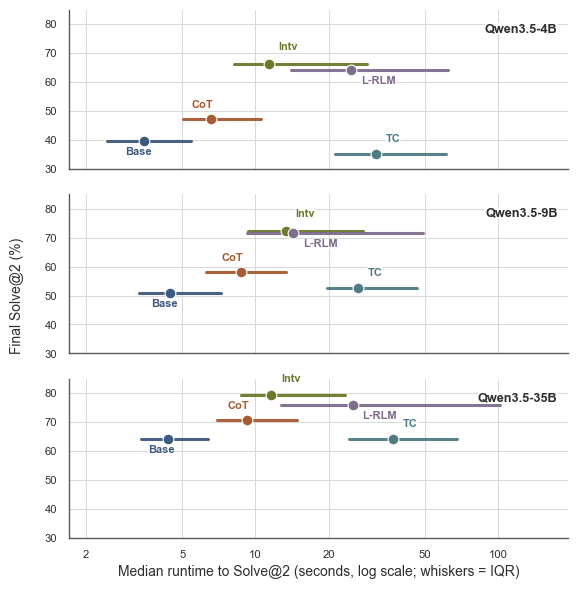

'analysis/figures/baseline_runtime_efficiency_frontier.pdf'

In [8]:
try:
    import numpy as np
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy and matplotlib. Install them in the notebook kernel, "
        "for example with `uv pip install numpy matplotlib`."
    ) from exc

required_names = [
    "runtime_efficiency_summary",
    "DIAGNOSTIC_MODEL_ORDER",
    "DIAGNOSTIC_MODEL_DISPLAY",
    "BASELINE_ORDER",
    "BASELINE_SHORT_DISPLAY",
    "apply_figure_style",
    "build_baseline_palette",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the results diagnostics prep cell first. Missing names: " + ", ".join(missing_names)
    )

runtime_style = apply_figure_style("distribution")
baseline_palette = build_baseline_palette(BASELINE_ORDER, runtime_style)
label_offsets = {
    "base-repair": (-14, -10),
    "cot-repair": (-14, 8),
    "intervenor": (7, 10),
    "lambda-rlm": (7, -10),
    "tracecoder": (7, 9),
}

x_values = runtime_efficiency_summary[
    ["median_runtime_sec", "runtime_q1_sec", "runtime_q3_sec"]
].to_numpy(dtype=float)
positive_values = x_values[np.isfinite(x_values) & (x_values > 0)]
x_min = float(positive_values.min() * 0.7)
x_max = float(positive_values.max() * 1.9)
y_min = float(np.floor((runtime_efficiency_summary["final_solve_at_2_pct"].min() - 3) / 5) * 5)
y_max = float(np.ceil((runtime_efficiency_summary["final_solve_at_2_pct"].max() + 4) / 5) * 5)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(5.9, 5.9),
    sharex=True,
    sharey=True,
)

for ax, model_size in zip(axes, DIAGNOSTIC_MODEL_ORDER):
    subset = runtime_efficiency_summary.loc[
        runtime_efficiency_summary["model_size"] == model_size
    ].copy()
    subset["baseline_order"] = subset["baseline"].map({baseline: i for i, baseline in enumerate(BASELINE_ORDER)})
    subset = subset.sort_values("baseline_order")
    ax.set_facecolor(runtime_style["axes_facecolor"])
    ax.set_xscale("log")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(True, axis="both", color=runtime_style["grid_color"], linewidth=runtime_style["grid_linewidth"])
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=runtime_style["tick_label_fontsize"])
    if runtime_style["hide_top_right_spines"]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    ax.text(
        0.98,
        0.92,
        DIAGNOSTIC_MODEL_DISPLAY[model_size],
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9.2,
        weight="bold",
        bbox=dict(runtime_style["annotation_bbox"]),
    )

    for row in subset.itertuples(index=False):
        color = baseline_palette[row.baseline]
        ax.plot(
            [row.runtime_q1_sec, row.runtime_q3_sec],
            [row.final_solve_at_2_pct, row.final_solve_at_2_pct],
            color=color,
            linewidth=2.2,
            solid_capstyle="round",
            alpha=0.95,
            zorder=2,
        )
        ax.scatter(
            row.median_runtime_sec,
            row.final_solve_at_2_pct,
            s=60,
            color=color,
            edgecolor="white",
            linewidth=0.8,
            zorder=3,
        )
        ax.annotate(
            BASELINE_SHORT_DISPLAY[row.baseline],
            xy=(row.median_runtime_sec, row.final_solve_at_2_pct),
            xytext=label_offsets[row.baseline],
            textcoords="offset points",
            fontsize=runtime_style["annotation_fontsize"],
            color=color,
            weight="bold",
            bbox=dict(runtime_style["annotation_bbox"]),
        )

runtime_ticks = [2, 5, 10, 20, 50, 100, 200]
runtime_ticks = [tick for tick in runtime_ticks if x_min <= tick <= x_max]
axes[-1].set_xticks(runtime_ticks)
axes[-1].set_xticklabels([str(tick) for tick in runtime_ticks])
axes[-1].set_xlabel(
    "Median runtime to Solve@2 (seconds, log scale; whiskers = IQR)",
    fontsize=runtime_style["axis_label_fontsize"],
)
fig.supylabel("Final Solve@2 (%)", fontsize=runtime_style["axis_label_fontsize"], x=0.04)
fig.subplots_adjust(left=0.14, right=0.985, top=0.985, bottom=0.09, hspace=0.16)

runtime_efficiency_figure_path = save_figure(
    fig,
    "baseline_runtime_efficiency_frontier.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(runtime_efficiency_figure_path)


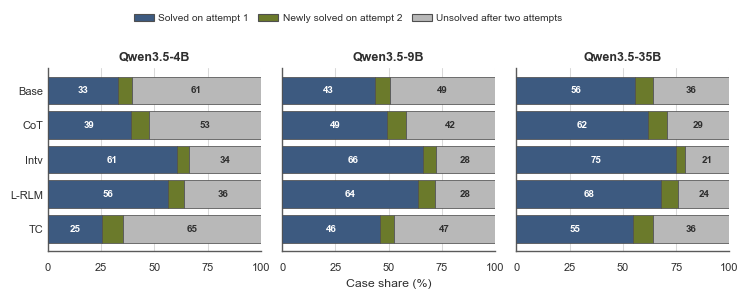

'analysis/figures/baseline_attempt_profile_stacked.pdf'

In [9]:
try:
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy and matplotlib. Install them in the notebook kernel, "
        "for example with `uv pip install numpy matplotlib`."
    ) from exc

required_names = [
    "attempt_profile_summary",
    "DIAGNOSTIC_MODEL_ORDER",
    "DIAGNOSTIC_MODEL_DISPLAY",
    "BASELINE_ORDER",
    "BASELINE_SHORT_DISPLAY",
    "apply_figure_style",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the results diagnostics prep cell first. Missing names: " + ", ".join(missing_names)
    )

bar_style = apply_figure_style("bars")
bucket_order = ["solved_attempt_1", "solved_attempt_2", "unsolved_after_2"]
bucket_labels = {
    "solved_attempt_1": "Solved on attempt 1",
    "solved_attempt_2": "Newly solved on attempt 2",
    "unsolved_after_2": "Unsolved after two attempts",
}
segment_colors = bar_style["attempt_outcome_colors"]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(7.7, 2.9),
    sharex=True,
    sharey=True,
)

y_positions = np.arange(len(BASELINE_ORDER), dtype=float)
for ax, model_size in zip(axes, DIAGNOSTIC_MODEL_ORDER):
    subset = attempt_profile_summary.loc[
        attempt_profile_summary["model_size"] == model_size
    ].pivot(index="baseline", columns="attempt_profile_bucket", values="share_pct")
    subset = subset.reindex(index=BASELINE_ORDER, columns=bucket_order, fill_value=0.0)

    left = np.zeros(len(BASELINE_ORDER), dtype=float)
    for bucket in bucket_order:
        values = subset[bucket].to_numpy(dtype=float)
        ax.barh(
            y_positions,
            values,
            left=left,
            color=segment_colors[bucket],
            edgecolor=bar_style["bar_edgecolor"],
            linewidth=0.55,
            zorder=3,
            label=bucket_labels[bucket],
        )
        for idx, value in enumerate(values):
            if value >= 12:
                ax.text(
                    left[idx] + value / 2,
                    y_positions[idx],
                    f"{value:.0f}",
                    ha="center",
                    va="center",
                    fontsize=7.0,
                    color="white" if bucket != "unsolved_after_2" else "#2F2F2F",
                    weight="bold",
                )
        left += values

    ax.set_facecolor(bar_style["axes_facecolor"])
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_title(DIAGNOSTIC_MODEL_DISPLAY[model_size], fontsize=9.0, weight="bold")
    ax.grid(True, axis="x", color=bar_style["grid_color"], linewidth=bar_style["grid_linewidth"])
    ax.grid(False, axis="y")
    ax.tick_params(axis="x", labelsize=bar_style["ytick_label_fontsize"])
    ax.tick_params(axis="y", length=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(bar_style["spine_color"])
    ax.spines["bottom"].set_color(bar_style["spine_color"])

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(
    [BASELINE_SHORT_DISPLAY[baseline] for baseline in BASELINE_ORDER],
    fontsize=bar_style["ytick_label_fontsize"],
)
axes[0].invert_yaxis()
for ax in axes[1:]:
    ax.tick_params(axis="y", labelleft=False)

axes[1].set_xlabel("Case share (%)", fontsize=bar_style["label_fontsize"], color=bar_style["label_color"])
fig.legend(
    handles=[
        Patch(facecolor=segment_colors[bucket], edgecolor=bar_style["bar_edgecolor"], label=bucket_labels[bucket])
        for bucket in bucket_order
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=5,
    frameon=bar_style["legend_frameon"],
    fontsize=bar_style["legend_fontsize"],
    columnspacing=0.9,
    handletextpad=0.45,
)
fig.subplots_adjust(left=0.11, right=0.995, top=0.80, bottom=0.17, wspace=0.10)

attempt_profile_figure_path = save_figure(
    fig,
    "baseline_attempt_profile_stacked.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(attempt_profile_figure_path)


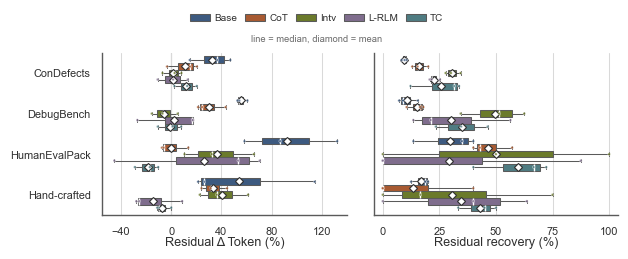

'analysis/figures/adaptive_residual_tradeoff_boxplot_pooled_baselines.pdf'

In [10]:
try:
    import numpy as np
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy, pandas, seaborn, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas seaborn matplotlib`."
    ) from exc

from matplotlib.patches import Patch

required_names = [
    "baseline_case_summary",
    "adaptive_case_summary",
    "ADAPTIVE_BASELINE_DISPLAY",
    "ADAPTIVE_BENCHMARK_DISPLAY",
    "REPO_ROOT",
    "apply_figure_style",
    "build_baseline_palette",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the adaptive summary cell first. Missing names: " + ", ".join(missing_names)
    )

# Separate baseline-colored boxplots require pooling across model sizes. At the
# per-model level, each baseline x benchmark combination contributes only one point,
# so a true boxplot would collapse to a single observation.
model_order = [4, 9, 35]
benchmark_order = [ADAPTIVE_BENCHMARK_DISPLAY[key] for key in ADAPTIVE_BENCHMARK_DISPLAY]
baseline_order = [ADAPTIVE_BASELINE_DISPLAY[key] for key in ADAPTIVE_BASELINE_DISPLAY]
baseline_legend_labels = {
    "Base Repair": "Base",
    "CoT Repair": "CoT",
    "Intervenor": "Intv",
    "Lambda-RLM": "L-RLM",
    "TraceCoder": "TC",
}
tuned_rows = []

for model_size in model_order:
    for baseline_key, baseline_label in ADAPTIVE_BASELINE_DISPLAY.items():
        for bug_source_key, benchmark_label in ADAPTIVE_BENCHMARK_DISPLAY.items():
            adaptive_group = adaptive_case_summary.loc[
                (adaptive_case_summary["model_size"] == model_size)
                & (adaptive_case_summary["baseline"] == baseline_key)
                & (adaptive_case_summary["bug_source"] == bug_source_key)
            ]
            if adaptive_group.empty:
                continue

            baseline_group = baseline_case_summary.loc[
                (baseline_case_summary["model_size"] == model_size)
                & (baseline_case_summary["baseline"] == baseline_key)
                & (baseline_case_summary["bug_source"] == bug_source_key)
            ]
            assert not baseline_group.empty, (
                f"Missing matching baseline run for {baseline_key} {model_size}B {bug_source_key}"
            )

            residual_failed_subset = baseline_group.loc[
                ~baseline_group["solve_at_2"],
                ["case_id", "total_tokens_per_task"],
            ].rename(columns={"total_tokens_per_task": "baseline_total_tokens_per_task"})

            adaptive_overlap = adaptive_group.merge(
                residual_failed_subset,
                on="case_id",
                how="inner",
            )
            assert len(adaptive_overlap) == len(residual_failed_subset), (
                f"Adaptive run coverage mismatch for {baseline_key} {model_size}B {bug_source_key}: "
                f"expected {len(residual_failed_subset)} failed cases, got {len(adaptive_overlap)}"
            )

            baseline_avg_tokens = residual_failed_subset["baseline_total_tokens_per_task"].mean()
            adaptive_avg_tokens = adaptive_overlap["total_tokens_per_task"].mean()
            tuned_rows.append(
                {
                    "model_size": model_size,
                    "model_label": f"Qwen3.5-{model_size}B",
                    "benchmark": benchmark_label,
                    "baseline": baseline_label,
                    "recovery_rate_pct": adaptive_overlap["solve_at_2"].mean() * 100,
                    "token_delta_pct": (
                        (adaptive_avg_tokens - baseline_avg_tokens) / baseline_avg_tokens * 100
                    )
                    if baseline_avg_tokens
                    else np.nan,
                    "residual_failed_n": len(residual_failed_subset),
                }
            )

adaptive_three_panel_tuned_plot_data = pd.DataFrame(tuned_rows)
assert not adaptive_three_panel_tuned_plot_data.empty, "No adaptive tradeoff plot data was generated."

adaptive_three_panel_tuned_means = pd.DataFrame(
    [
        {
            "model_size": model_size,
            "token_delta_pct": np.average(group["token_delta_pct"], weights=group["residual_failed_n"]),
            "recovery_rate_pct": np.average(group["recovery_rate_pct"], weights=group["residual_failed_n"]),
        }
        for model_size in model_order
        for group in [
            adaptive_three_panel_tuned_plot_data.loc[
                adaptive_three_panel_tuned_plot_data["model_size"] == model_size
            ]
        ]
        if not group.empty
    ]
)

adaptive_boxplot_pooled_data = adaptive_three_panel_tuned_plot_data.copy()
adaptive_boxplot_pooled_data["benchmark"] = pd.Categorical(
    adaptive_boxplot_pooled_data["benchmark"], categories=benchmark_order, ordered=True
)
adaptive_boxplot_pooled_data["baseline"] = pd.Categorical(
    adaptive_boxplot_pooled_data["baseline"], categories=baseline_order, ordered=True
)

box_style = apply_figure_style("distribution")
baseline_palette = build_baseline_palette(baseline_order, box_style)

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(6.7, 2.75),
    sharey=True,
)
metric_specs = [
    {
        "column": "token_delta_pct",
        "title": "Token delta",
        "label": "Residual Δ Token (%)",
        "xlim": (-55, 140),
        "xticks": [-40, 0, 40, 80, 120],
        "show_zero": True,
    },
    {
        "column": "recovery_rate_pct",
        "title": "Recovery rate",
        "label": "Residual recovery (%)",
        "xlim": (-4, 104),
        "xticks": [0, 25, 50, 75, 100],
        "show_zero": False,
    },
]

for ax, spec in zip(axes, metric_specs):
    ax.set_facecolor(box_style["axes_facecolor"])
    sns.boxplot(
        data=adaptive_boxplot_pooled_data,
        x=spec["column"],
        y="benchmark",
        hue="baseline",
        order=benchmark_order,
        hue_order=baseline_order,
        orient="h",
        dodge=True,
        width=0.82,
        linewidth=0.75,
        fliersize=0,
        showmeans=True,
        saturation=1,
        palette=baseline_palette,
        boxprops={"edgecolor": box_style["box_edgecolor"]},
        whiskerprops={"color": box_style["box_edgecolor"], "linewidth": 0.75},
        capprops={"color": box_style["box_edgecolor"], "linewidth": 0.75},
        medianprops={"color": "white", "linewidth": 1.0},
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "#2F2F2F",
            "markeredgewidth": 0.8,
            "markersize": 4.4,
        },
        ax=ax,
    )
    sns.stripplot(
        data=adaptive_boxplot_pooled_data,
        x=spec["column"],
        y="benchmark",
        hue="baseline",
        order=benchmark_order,
        hue_order=baseline_order,
        orient="h",
        dodge=True,
        jitter=False,
        size=1.9,
        edgecolor="white",
        linewidth=0.3,
        palette=baseline_palette,
        alpha=0.78,
        ax=ax,
        zorder=3,
    )
    if ax.legend_ is not None:
        ax.legend_.remove()
    if spec["show_zero"]:
        ax.axvline(0, color="#CFCFCF", linewidth=0.85, zorder=0)
    ax.set_xlim(*spec["xlim"])
    ax.set_xticks(spec["xticks"])
    ax.grid(True, axis="x", color=box_style["grid_color"], linewidth=box_style["grid_linewidth"])
    ax.grid(False, axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=7.8)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if ax is not axes[0]:
        ax.tick_params(axis="y", labelleft=False, left=False)
    if box_style["hide_top_right_spines"]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(box_style["box_edgecolor"])
    ax.spines["bottom"].set_color(box_style["box_edgecolor"])

fig.legend(
    handles=[
        Patch(
            facecolor=baseline_palette[baseline],
            edgecolor=box_style["box_edgecolor"],
            linewidth=0.75,
            label=baseline_legend_labels[baseline],
        )
        for baseline in baseline_order
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=box_style["legend_frameon"],
    fontsize=7.2,
    columnspacing=0.8,
    handletextpad=0.4,
)
fig.subplots_adjust(left=0.18, right=0.95, top=0.82, bottom=0.23, wspace=0.11)
fig.text(
    0.5,
    0.855,
    "line = median, diamond = mean",
    ha="center",
    va="bottom",
    fontsize=6.7,
    color=box_style["muted_text_color"],
)

for ax, spec in zip(axes, metric_specs):
    bbox = ax.get_position()
    panel_center_x = (bbox.x0 + bbox.x1) / 2
    fig.text(
        panel_center_x,
        bbox.y0 - 0.08,
        spec["label"],
        ha="center",
        va="top",
        fontsize=9.1,
    )

adaptive_boxplot_figure_path = save_figure(
    fig,
    "adaptive_residual_tradeoff_boxplot_pooled_baselines.png",
    dpi=300,
)
adaptive_three_panel_tuned_figure_path = adaptive_boxplot_figure_path
show_figure(fig)
repo_relative_path(adaptive_three_panel_tuned_figure_path)








### Broken Token-Axis Alternative

This alternative keeps the scale linear but splits the token-delta axis into a dense region and a high-value tail, which makes the smaller pooled boxplots easier to compare without using a nonlinear transform.



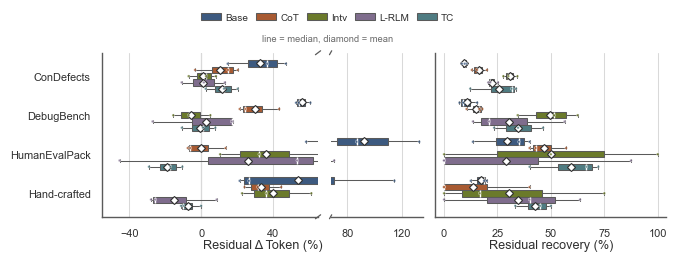

'analysis/figures/adaptive_residual_tradeoff_boxplot_broken_token_axis.pdf'

In [11]:
try:
    import numpy as np
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy, pandas, seaborn, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas seaborn matplotlib`."
    ) from exc

from matplotlib.patches import Patch

required_names = [
    "adaptive_three_panel_tuned_plot_data",
    "ADAPTIVE_BASELINE_DISPLAY",
    "ADAPTIVE_BENCHMARK_DISPLAY",
    "apply_figure_style",
    "build_baseline_palette",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the adaptive summary and styling cells first. Missing names: " + ", ".join(missing_names)
    )

benchmark_order = [ADAPTIVE_BENCHMARK_DISPLAY[key] for key in ADAPTIVE_BENCHMARK_DISPLAY]
baseline_order = [ADAPTIVE_BASELINE_DISPLAY[key] for key in ADAPTIVE_BASELINE_DISPLAY]
baseline_legend_labels = {
    "Base Repair": "Base",
    "CoT Repair": "CoT",
    "Intervenor": "Intv",
    "Lambda-RLM": "L-RLM",
    "TraceCoder": "TC",
}

adaptive_boxplot_broken_data = adaptive_three_panel_tuned_plot_data.copy()
adaptive_boxplot_broken_data["benchmark"] = pd.Categorical(
    adaptive_boxplot_broken_data["benchmark"], categories=benchmark_order, ordered=True
)
adaptive_boxplot_broken_data["baseline"] = pd.Categorical(
    adaptive_boxplot_broken_data["baseline"], categories=baseline_order, ordered=True
)

box_style = apply_figure_style("distribution")
baseline_palette = build_baseline_palette(baseline_order, box_style)


def draw_boxplot_panel(ax, *, column, xlim, xticks, show_zero=False):
    ax.set_facecolor(box_style["axes_facecolor"])
    sns.boxplot(
        data=adaptive_boxplot_broken_data,
        x=column,
        y="benchmark",
        hue="baseline",
        order=benchmark_order,
        hue_order=baseline_order,
        orient="h",
        dodge=True,
        width=0.82,
        linewidth=0.75,
        fliersize=0,
        showmeans=True,
        saturation=1,
        palette=baseline_palette,
        boxprops={"edgecolor": box_style["box_edgecolor"]},
        whiskerprops={"color": box_style["box_edgecolor"], "linewidth": 0.75},
        capprops={"color": box_style["box_edgecolor"], "linewidth": 0.75},
        medianprops={"color": "white", "linewidth": 1.0},
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": "#2F2F2F",
            "markeredgewidth": 0.8,
            "markersize": 4.4,
        },
        ax=ax,
    )
    sns.stripplot(
        data=adaptive_boxplot_broken_data,
        x=column,
        y="benchmark",
        hue="baseline",
        order=benchmark_order,
        hue_order=baseline_order,
        orient="h",
        dodge=True,
        jitter=False,
        size=1.9,
        edgecolor="white",
        linewidth=0.3,
        palette=baseline_palette,
        alpha=0.78,
        ax=ax,
        zorder=3,
    )
    if ax.legend_ is not None:
        ax.legend_.remove()
    if show_zero:
        ax.axvline(0, color="#CFCFCF", linewidth=0.85, zorder=0)
    ax.set_xlim(*xlim)
    ax.set_xticks(xticks)
    ax.grid(True, axis="x", color=box_style["grid_color"], linewidth=box_style["grid_linewidth"])
    ax.grid(False, axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=7.8)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if box_style["hide_top_right_spines"]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(box_style["box_edgecolor"])
    ax.spines["bottom"].set_color(box_style["box_edgecolor"])


fig = plt.figure(figsize=(7.05, 2.78))
grid = fig.add_gridspec(1, 3, width_ratios=[2.15, 0.92, 2.30], wspace=0.07)
ax_token_lo = fig.add_subplot(grid[0, 0])
ax_token_hi = fig.add_subplot(grid[0, 1], sharey=ax_token_lo)
ax_recovery = fig.add_subplot(grid[0, 2], sharey=ax_token_lo)

draw_boxplot_panel(
    ax_token_lo,
    column="token_delta_pct",
    xlim=(-55, 65),
    xticks=[-40, 0, 40],
    show_zero=True,
)
draw_boxplot_panel(
    ax_token_hi,
    column="token_delta_pct",
    xlim=(68, 135),
    xticks=[80, 120],
)
draw_boxplot_panel(
    ax_recovery,
    column="recovery_rate_pct",
    xlim=(-4, 104),
    xticks=[0, 25, 50, 75, 100],
)

ax_token_lo.set_yticks(np.arange(len(benchmark_order), dtype=float))
ax_token_lo.set_yticklabels(benchmark_order, fontsize=7.8)
ax_token_hi.tick_params(axis="y", labelleft=False, left=False)
ax_recovery.tick_params(axis="y", labelleft=False, left=False)

ax_token_lo.spines["right"].set_visible(False)
ax_token_hi.spines["left"].set_visible(False)
ax_token_hi.tick_params(axis="y", left=False)
break_size = 0.012
break_kwargs = dict(color=box_style["box_edgecolor"], clip_on=False, linewidth=0.9)
ax_token_lo.plot((1 - break_size, 1 + break_size), (-break_size, +break_size), transform=ax_token_lo.transAxes, **break_kwargs)
ax_token_lo.plot((1 - break_size, 1 + break_size), (1 - break_size, 1 + break_size), transform=ax_token_lo.transAxes, **break_kwargs)
ax_token_hi.plot((-break_size, +break_size), (-break_size, +break_size), transform=ax_token_hi.transAxes, **break_kwargs)
ax_token_hi.plot((-break_size, +break_size), (1 - break_size, 1 + break_size), transform=ax_token_hi.transAxes, **break_kwargs)

fig.legend(
    handles=[
        Patch(
            facecolor=baseline_palette[baseline],
            edgecolor=box_style["box_edgecolor"],
            linewidth=0.75,
            label=baseline_legend_labels[baseline],
        )
        for baseline in baseline_order
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=box_style["legend_frameon"],
    fontsize=7.2,
    columnspacing=0.8,
    handletextpad=0.4,
)
fig.subplots_adjust(left=0.18, right=0.98, top=0.82, bottom=0.23)
fig.text(
    0.5,
    0.855,
    "line = median, diamond = mean",
    ha="center",
    va="bottom",
    fontsize=6.7,
    color=box_style["muted_text_color"],
)

token_lo_bbox = ax_token_lo.get_position()
token_hi_bbox = ax_token_hi.get_position()
recovery_bbox = ax_recovery.get_position()
token_center_x = (token_lo_bbox.x0 + token_hi_bbox.x1) / 2
recovery_center_x = (recovery_bbox.x0 + recovery_bbox.x1) / 2
label_y = token_lo_bbox.y0 - 0.08
fig.text(token_center_x, label_y, "Residual Δ Token (%)", ha="center", va="top", fontsize=9.1)
fig.text(recovery_center_x, label_y, "Residual recovery (%)", ha="center", va="top", fontsize=9.1)

adaptive_boxplot_broken_token_axis_figure_path = save_figure(
    fig,
    "adaptive_residual_tradeoff_boxplot_broken_token_axis.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(adaptive_boxplot_broken_token_axis_figure_path)


### Dot-Interval Alternative

This alternative is a more literal summary for the pooled-across-models view: each small dot is one model-size observation, the thick line shows the min-max span across model sizes, and the larger dot marks the simple mean of the displayed points.



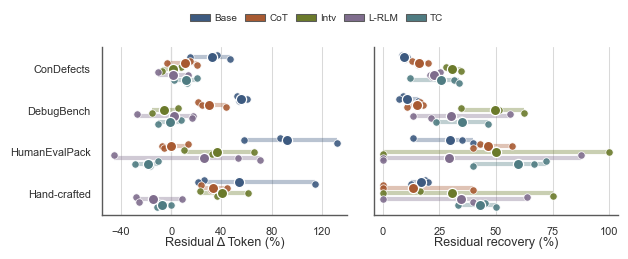

'analysis/figures/adaptive_residual_tradeoff_dotinterval_pooled_baselines.pdf'

In [12]:
try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy, pandas, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas matplotlib`."
    ) from exc

from matplotlib.patches import Patch

required_names = [
    "adaptive_three_panel_tuned_plot_data",
    "ADAPTIVE_BASELINE_DISPLAY",
    "ADAPTIVE_BENCHMARK_DISPLAY",
    "apply_figure_style",
    "build_baseline_palette",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the adaptive summary and styling cells first. Missing names: " + ", ".join(missing_names)
    )

benchmark_order = [ADAPTIVE_BENCHMARK_DISPLAY[key] for key in ADAPTIVE_BENCHMARK_DISPLAY]
baseline_order = [ADAPTIVE_BASELINE_DISPLAY[key] for key in ADAPTIVE_BASELINE_DISPLAY]
baseline_legend_labels = {
    "Base Repair": "Base",
    "CoT Repair": "CoT",
    "Intervenor": "Intv",
    "Lambda-RLM": "L-RLM",
    "TraceCoder": "TC",
}

dot_style = apply_figure_style("distribution")
baseline_palette = build_baseline_palette(baseline_order, dot_style)
baseline_offsets = dict(zip(baseline_order, np.linspace(-0.28, 0.28, len(baseline_order))))
benchmark_positions = {benchmark: idx for idx, benchmark in enumerate(benchmark_order)}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.7, 2.75),
    sharey=True,
)
metric_specs = [
    {
        "column": "token_delta_pct",
        "label": "Residual Δ Token (%)",
        "xlim": (-55, 140),
        "xticks": [-40, 0, 40, 80, 120],
        "show_zero": True,
    },
    {
        "column": "recovery_rate_pct",
        "label": "Residual recovery (%)",
        "xlim": (-4, 104),
        "xticks": [0, 25, 50, 75, 100],
        "show_zero": False,
    },
]

for ax, spec in zip(axes, metric_specs):
    ax.set_facecolor(dot_style["axes_facecolor"])
    for benchmark in benchmark_order:
        benchmark_df = adaptive_three_panel_tuned_plot_data.loc[
            adaptive_three_panel_tuned_plot_data["benchmark"] == benchmark
        ]
        for baseline in baseline_order:
            group = benchmark_df.loc[benchmark_df["baseline"] == baseline].sort_values("model_size")
            if group.empty:
                continue

            values = group[spec["column"]].to_numpy(dtype=float)
            center_y = benchmark_positions[benchmark] + baseline_offsets[baseline]
            raw_offsets = np.linspace(-0.055, 0.055, len(values)) if len(values) > 1 else np.array([0.0])
            raw_y = center_y + raw_offsets

            ax.hlines(
                center_y,
                float(np.nanmin(values)),
                float(np.nanmax(values)),
                color=baseline_palette[baseline],
                linewidth=3.0,
                alpha=0.36,
                zorder=1,
            )
            ax.scatter(
                values,
                raw_y,
                s=28,
                color=baseline_palette[baseline],
                edgecolor="white",
                linewidth=0.55,
                alpha=0.9,
                zorder=3,
            )
            ax.scatter(
                float(np.nanmean(values)),
                center_y,
                s=54,
                color=baseline_palette[baseline],
                edgecolor="white",
                linewidth=0.9,
                zorder=4,
            )

    if spec["show_zero"]:
        ax.axvline(0, color="#CFCFCF", linewidth=0.85, zorder=0)
    ax.set_xlim(*spec["xlim"])
    ax.set_xticks(spec["xticks"])
    ax.set_yticks(np.arange(len(benchmark_order), dtype=float))
    ax.grid(True, axis="x", color=dot_style["grid_color"], linewidth=dot_style["grid_linewidth"])
    ax.grid(False, axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=7.8)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if dot_style["hide_top_right_spines"]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(dot_style["box_edgecolor"])
    ax.spines["bottom"].set_color(dot_style["box_edgecolor"])

axes[0].set_yticklabels(benchmark_order, fontsize=7.8)
axes[0].invert_yaxis()
axes[1].tick_params(axis="y", labelleft=False, left=False)

fig.legend(
    handles=[
        Patch(
            facecolor=baseline_palette[baseline],
            edgecolor=dot_style["box_edgecolor"],
            linewidth=0.75,
            label=baseline_legend_labels[baseline],
        )
        for baseline in baseline_order
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=dot_style["legend_frameon"],
    fontsize=7.2,
    columnspacing=0.8,
    handletextpad=0.4,
)
fig.subplots_adjust(left=0.18, right=0.95, top=0.84, bottom=0.23, wspace=0.11)

for ax, spec in zip(axes, metric_specs):
    bbox = ax.get_position()
    panel_center_x = (bbox.x0 + bbox.x1) / 2
    fig.text(
        panel_center_x,
        bbox.y0 - 0.08,
        spec["label"],
        ha="center",
        va="top",
        fontsize=9.1,
    )

adaptive_dotinterval_figure_path = save_figure(
    fig,
    "adaptive_residual_tradeoff_dotinterval_pooled_baselines.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(adaptive_dotinterval_figure_path)


### Exploratory KDE Alternatives

These variants follow Seaborn gallery patterns, but they intentionally pool across models or benchmarks where needed because per-slice groups here often have only 5 observations. Treat them as exploratory views of the same residual tradeoff table rather than as a stronger summary than the box+strip figure above.



In [13]:
try:
    import numpy as np
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "These KDE figure cells use numpy, pandas, seaborn, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas seaborn matplotlib`."
    ) from exc

from matplotlib.lines import Line2D

required_names = [
    "adaptive_three_panel_tuned_plot_data",
    "ADAPTIVE_BENCHMARK_DISPLAY",
    "apply_figure_style",
    "build_benchmark_palette",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the residual tradeoff figure cell first. Missing names: " + ", ".join(missing_names)
    )

adaptive_kde_variant_plot_data = adaptive_three_panel_tuned_plot_data.copy()
assert not adaptive_kde_variant_plot_data.empty, "No residual tradeoff data is available for KDE variants."

benchmark_order = [ADAPTIVE_BENCHMARK_DISPLAY[key] for key in ADAPTIVE_BENCHMARK_DISPLAY]
scatter_style = apply_figure_style("scatter")
distribution_style = apply_figure_style("distribution")
benchmark_palette = build_benchmark_palette(benchmark_order, scatter_style)

model_display = {
    4: "Qwen3.5-4B",
    9: "Qwen3.5-9B",
    35: "Qwen3.5-35B",
}
model_palette = {
    model_display[model_size]: PAPER_MODEL_COLORS[model_size]
    for model_size in model_display
}
model_marker_map = {
    "Qwen3.5-4B": "o",
    "Qwen3.5-9B": "s",
    "Qwen3.5-35B": "D",
}

adaptive_kde_variant_plot_data["benchmark"] = pd.Categorical(
    adaptive_kde_variant_plot_data["benchmark"],
    categories=benchmark_order,
    ordered=True,
)
adaptive_kde_variant_plot_data["model_label"] = adaptive_kde_variant_plot_data["model_size"].map(model_display)
adaptive_kde_variant_plot_data["model_label"] = pd.Categorical(
    adaptive_kde_variant_plot_data["model_label"],
    categories=[model_display[size] for size in sorted(model_display) if size in set(adaptive_kde_variant_plot_data["model_size"])],
    ordered=True,
)

# 1) Joint KDE: tighter contours by model size, with weighted means overlaid.
scatter_style = apply_figure_style("scatter")
joint_grid = sns.JointGrid(
    data=adaptive_kde_variant_plot_data,
    x="token_delta_pct",
    y="recovery_rate_pct",
    height=3.45,
    ratio=5,
    space=0.04,
    xlim=(-45, 135),
    ylim=(0, 100),
)
for model_label in adaptive_kde_variant_plot_data["model_label"].cat.categories:
    group = adaptive_kde_variant_plot_data.loc[
        adaptive_kde_variant_plot_data["model_label"] == model_label
    ]
    color = model_palette[str(model_label)]
    sns.kdeplot(
        data=group,
        x="token_delta_pct",
        y="recovery_rate_pct",
        fill=True,
        alpha=0.14,
        thresh=0.38,
        levels=4,
        bw_adjust=0.68,
        cut=0,
        clip=[(-45, 135), (0, 100)],
        color=color,
        warn_singular=False,
        ax=joint_grid.ax_joint,
    )
    sns.kdeplot(
        data=group,
        x="token_delta_pct",
        y="recovery_rate_pct",
        fill=False,
        thresh=0.38,
        levels=4,
        bw_adjust=0.68,
        cut=0,
        clip=[(-45, 135), (0, 100)],
        color=color,
        linewidths=1.25,
        warn_singular=False,
        ax=joint_grid.ax_joint,
    )
    sns.kdeplot(
        data=group,
        x="token_delta_pct",
        bw_adjust=0.72,
        cut=0,
        clip=(-45, 135),
        color=color,
        linewidth=1.2,
        fill=False,
        warn_singular=False,
        ax=joint_grid.ax_marg_x,
    )
    sns.kdeplot(
        data=group,
        y="recovery_rate_pct",
        bw_adjust=0.72,
        cut=0,
        clip=(0, 100),
        color=color,
        linewidth=1.2,
        fill=False,
        warn_singular=False,
        ax=joint_grid.ax_marg_y,
    )
    joint_grid.ax_joint.scatter(
        group["token_delta_pct"],
        group["recovery_rate_pct"],
        s=14,
        color=color,
        alpha=0.55,
        edgecolor="white",
        linewidth=0.25,
        zorder=4,
    )
    joint_grid.ax_joint.scatter(
        np.average(group["token_delta_pct"], weights=group["residual_failed_n"]),
        np.average(group["recovery_rate_pct"], weights=group["residual_failed_n"]),
        s=72,
        marker="X",
        c=[color],
        edgecolor="#202020",
        linewidth=0.45,
        zorder=6,
    )

joint_grid.ax_joint.axvline(0, color="#CFCFCF", linewidth=0.85, zorder=0)
joint_grid.ax_joint.grid(True, color=scatter_style["grid_color"], linewidth=scatter_style["grid_linewidth"])
joint_grid.ax_joint.set_xlabel("Residual Δ Token (%)", fontsize=8.8)
joint_grid.ax_joint.set_ylabel("Residual recovery (%)", fontsize=8.8)
joint_grid.ax_joint.tick_params(axis="both", labelsize=7.2)
joint_grid.ax_marg_x.tick_params(axis="x", labelbottom=False)
joint_grid.ax_marg_x.tick_params(axis="y", left=False, labelleft=False)
joint_grid.ax_marg_y.tick_params(axis="y", labelleft=False)
joint_grid.ax_marg_y.tick_params(axis="x", bottom=False, labelbottom=False)
joint_grid.ax_marg_x.grid(False)
joint_grid.ax_marg_y.grid(False)
joint_grid.ax_joint.legend(
    handles=[
        Line2D(
            [0],
            [0],
            color=model_palette[model_label],
            lw=1.8,
            marker="X",
            markersize=6.0,
            markerfacecolor=model_palette[model_label],
            markeredgecolor="#202020",
            markeredgewidth=0.45,
            label=model_label,
        )
        for model_label in adaptive_kde_variant_plot_data["model_label"].cat.categories
    ],
    loc="upper right",
    frameon=True,
    framealpha=0.92,
    fontsize=6.9,
    title="Model",
    title_fontsize=7.1,
)
adaptive_joint_kde_figure_path = save_figure(
    joint_grid.figure,
    "adaptive_residual_tradeoff_joint_kde.png",
    dpi=300,
)
plt.close(joint_grid.figure)

# 2) Ridge plot: token-delta density by benchmark, pooled across models.
sns.set_theme(
    style="white",
    context=distribution_style["theme"].get("context", "paper"),
    rc={**distribution_style["rc"], "axes.facecolor": (0, 0, 0, 0)},
)
ridge_grid = sns.FacetGrid(
    adaptive_kde_variant_plot_data,
    row="benchmark",
    hue="benchmark",
    row_order=benchmark_order,
    aspect=6.0,
    height=0.72,
    palette=benchmark_palette,
)
ridge_grid.map(
    sns.kdeplot,
    "token_delta_pct",
    bw_adjust=0.95,
    clip_on=False,
    fill=True,
    alpha=0.86,
    linewidth=1.1,
    clip=(-50, 140),
    warn_singular=False,
)
ridge_grid.map(
    sns.kdeplot,
    "token_delta_pct",
    bw_adjust=0.95,
    clip_on=False,
    color="white",
    lw=1.15,
    clip=(-50, 140),
    warn_singular=False,
)
ridge_grid.refline(
    y=0,
    linewidth=1.0,
    linestyle="-",
    color=distribution_style["line_color"],
    clip_on=False,
)


def annotate_ridge_label(x, color, label):
    ax = plt.gca()
    ax.text(
        0.07,
        0.24,
        label,
        fontweight="bold",
        color=color,
        ha="left",
        va="center",
        transform=ax.transAxes,
        fontsize=distribution_style["annotation_fontsize"] + 0.4,
    )


ridge_grid.map(annotate_ridge_label, "token_delta_pct")
ridge_grid.figure.subplots_adjust(hspace=-0.28)
ridge_grid.set_titles("")
ridge_grid.set(yticks=[], ylabel="", xlim=(-50, 140), xticks=[-40, 0, 40, 80, 120])
for ax in ridge_grid.axes.flat:
    ax.set_facecolor((0, 0, 0, 0))
ridge_grid.despine(bottom=True, left=True)
ridge_grid.set_xlabels("Residual Δ Token (%)")
adaptive_kde_ridgeplot_figure_path = save_figure(
    ridge_grid.figure,
    "adaptive_residual_tradeoff_kde_ridgeplot.png",
    dpi=300,
)
plt.close(ridge_grid.figure)

# 3) Multiple bivariate KDE: benchmark contours with model markers overlaid.
scatter_style = apply_figure_style("scatter")
bivariate_fig, bivariate_ax = plt.subplots(figsize=(6.25, 5.05))
sns.kdeplot(
    data=adaptive_kde_variant_plot_data,
    x="token_delta_pct",
    y="recovery_rate_pct",
    hue="benchmark",
    hue_order=benchmark_order,
    palette=benchmark_palette,
    thresh=0.16,
    levels=4,
    linewidths=1.5,
    warn_singular=False,
    ax=bivariate_ax,
)
if bivariate_ax.legend_ is not None:
    bivariate_ax.legend_.remove()
for model_label, group in adaptive_kde_variant_plot_data.groupby("model_label", sort=False):
    bivariate_ax.scatter(
        group["token_delta_pct"],
        group["recovery_rate_pct"],
        s=26,
        marker=model_marker_map[str(model_label)],
        c="white",
        edgecolors="#4A4A4A",
        linewidths=0.55,
        alpha=0.86,
        zorder=4,
    )
benchmark_handles = [
    Line2D([0], [0], color=benchmark_palette[benchmark], lw=1.8, label=benchmark)
    for benchmark in benchmark_order
]
model_handles = [
    Line2D(
        [0],
        [0],
        marker=model_marker_map[model_label],
        linestyle="None",
        color="none",
        markerfacecolor="white",
        markeredgecolor="#4A4A4A",
        markeredgewidth=0.55,
        markersize=6.2,
        label=model_label,
    )
    for model_label in adaptive_kde_variant_plot_data["model_label"].cat.categories
]
bivariate_fig.legend(
    handles=benchmark_handles + model_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=4,
    frameon=False,
    fontsize=scatter_style["legend_fontsize"],
    columnspacing=0.8,
    handletextpad=0.45,
)
bivariate_ax.grid(True, color=scatter_style["grid_color"], linewidth=scatter_style["grid_linewidth"])
bivariate_ax.set_xlim(-50, 140)
bivariate_ax.set_ylim(0, 100)
bivariate_ax.set_xlabel("Residual Δ Token (%)")
bivariate_ax.set_ylabel("Residual recovery (%)")
bivariate_fig.subplots_adjust(top=0.87)
adaptive_multiple_bivariate_kde_figure_path = save_figure(
    bivariate_fig,
    "adaptive_residual_tradeoff_multiple_bivariate_kde.png",
    dpi=300,
)
plt.close(bivariate_fig)

# 4) Conditional KDE: benchmark density share across the token-delta axis.
distribution_style = apply_figure_style("distribution")
conditional_grid = sns.displot(
    data=adaptive_kde_variant_plot_data,
    x="token_delta_pct",
    hue="benchmark",
    hue_order=benchmark_order,
    kind="kde",
    multiple="fill",
    clip=(-50, 140),
    bw_adjust=0.95,
    warn_singular=False,
    height=4.6,
    aspect=1.35,
    palette=benchmark_palette,
)
if conditional_grid._legend is not None:
    conditional_grid._legend.set_title("Benchmark")
conditional_grid.set_axis_labels("Residual Δ Token (%)", "Conditional density share")
conditional_grid.set(xlim=(-50, 140), ylim=(0, 1))
adaptive_multiple_conditional_kde_figure_path = save_figure(
    conditional_grid.figure,
    "adaptive_residual_tradeoff_multiple_conditional_kde.png",
    dpi=300,
)
plt.close(conditional_grid.figure)

adaptive_kde_variant_figure_paths = {
    "joint_kde": adaptive_joint_kde_figure_path,
    "kde_ridgeplot": adaptive_kde_ridgeplot_figure_path,
    "multiple_bivariate_kde": adaptive_multiple_bivariate_kde_figure_path,
    "multiple_conditional_kde": adaptive_multiple_conditional_kde_figure_path,
}
repo_relative_paths(adaptive_kde_variant_figure_paths)



{'joint_kde': 'analysis/figures/adaptive_residual_tradeoff_joint_kde.pdf',
 'kde_ridgeplot': 'analysis/figures/adaptive_residual_tradeoff_kde_ridgeplot.pdf',
 'multiple_bivariate_kde': 'analysis/figures/adaptive_residual_tradeoff_multiple_bivariate_kde.pdf',
 'multiple_conditional_kde': 'analysis/figures/adaptive_residual_tradeoff_multiple_conditional_kde.pdf'}

## Policy Analysis

These cells analyze helper-policy dynamics over run progress, action enrichment on recovered decisions, and overall-versus-recovered action mixes for helper and budget policies.


In [14]:
try:
    import numpy as np
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This policy analysis cell uses numpy and pandas. Install them in the notebook kernel, "
        "for example with `uv pip install numpy pandas`."
    ) from exc

required_names = [
    "policy_datapoints",
    "budget_policy_datapoints",
    "read_jsonl_records",
    "REPO_ROOT",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the registry cell first. Missing names: " + ", ".join(missing_names)
    )

POLICY_BASELINE_DISPLAY = {
    "base-repair": "Base Repair",
    "cot-repair": "CoT Repair",
    "intervenor": "Intervenor",
    "lambda-rlm": "Lambda-RLM",
    "tracecoder": "TraceCoder",
}
POLICY_MODEL_ORDER = [4, 9, 35]
POLICY_MODEL_DISPLAY = {
    4: "Qwen3.5-4B",
    9: "Qwen3.5-9B",
    35: "Qwen3.5-35B",
}
HELPER_ACTION_ORDER = [
    "invoke_helper",
    "frame_locals_lite",
    "snapshot_lite",
    "snapshot_full_lite",
    "skip_helper",
    "file_only",
    "frame_only",
    "search_only",
    "compact_then_patch",
    "retry_helper_strict_json",
]
HELPER_ACTION_DISPLAY = {
    "invoke_helper": "invoke",
    "frame_locals_lite": "frame+locals",
    "snapshot_lite": "snap-lite",
    "snapshot_full_lite": "snap-full",
    "skip_helper": "skip",
    "file_only": "file",
    "frame_only": "frame",
    "search_only": "search",
    "compact_then_patch": "compact",
    "retry_helper_strict_json": "retry-json",
}
BUDGET_ACTION_ORDER = ["keep_budget", "increase_budget"]
BUDGET_ACTION_DISPLAY = {
    "keep_budget": "keep",
    "increase_budget": "increase",
}
POLICY_PROGRESS_BINS = 12
POLICY_PROGRESS_CENTERS = [
    (bin_index - 0.5) / POLICY_PROGRESS_BINS * 100 for bin_index in range(1, POLICY_PROGRESS_BINS + 1)
]


def policy_event_key(record: dict[str, object]) -> tuple[str, str, str, int, str]:
    return (
        str(record.get("run_id") or ""),
        str(record.get("case_id") or ""),
        str(record.get("condition") or ""),
        int(record.get("attempt") or 0),
        str(record.get("decision_id") or record.get("created_at_utc") or "unknown"),
    )


def load_policy_event_frame(datapoints, *, action_display: dict[str, str]) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    for datapoint in datapoints:
        deduped_records: dict[tuple[str, str, str, int, str], dict[str, object]] = {}
        for record in read_jsonl_records(datapoint.path):
            deduped_records[policy_event_key(record)] = record
        records = sorted(
            deduped_records.values(),
            key=lambda record: (
                str(record.get("created_at_utc") or ""),
                str(record.get("case_id") or ""),
                int(record.get("attempt") or 0),
                str(record.get("decision_id") or ""),
            ),
        )
        total_events = len(records)
        for event_order, record in enumerate(records, start=1):
            progress_frac = event_order / total_events if total_events else np.nan
            progress_bin = min(int(np.ceil(progress_frac * POLICY_PROGRESS_BINS)), POLICY_PROGRESS_BINS)
            selected_action = str(record.get("selected_action") or "")
            rows.append(
                {
                    "baseline": datapoint.baseline,
                    "baseline_display": POLICY_BASELINE_DISPLAY.get(datapoint.baseline, datapoint.baseline),
                    "model_size": datapoint.model_size,
                    "model_display": POLICY_MODEL_DISPLAY.get(datapoint.model_size, f"{datapoint.model_size}B"),
                    "run_id": str(record.get("run_id") or ""),
                    "case_id": str(record.get("case_id") or ""),
                    "attempt": int(record.get("attempt") or 0),
                    "decision_id": str(record.get("decision_id") or ""),
                    "created_at_utc": str(record.get("created_at_utc") or ""),
                    "event_order": event_order,
                    "events_in_run": total_events,
                    "progress_frac": progress_frac,
                    "progress_bin": progress_bin,
                    "progress_center_pct": (progress_bin - 0.5) / POLICY_PROGRESS_BINS * 100,
                    "selected_action": selected_action,
                    "selected_action_display": action_display.get(selected_action, selected_action),
                    "applied_action": str(record.get("applied_action") or ""),
                    "behavior_action": str(record.get("behavior_action") or ""),
                    "decision_strategy": str(record.get("decision_strategy") or ""),
                    "reward": float(record.get("reward") or 0.0),
                    "success": bool(record.get("success")),
                    "override_reason": str(record.get("override_reason") or ""),
                }
            )
    return pd.DataFrame(rows)


def action_distribution(events: pd.DataFrame, action_order: list[str]) -> np.ndarray:
    counts = events["selected_action"].value_counts()
    vector = np.asarray([float(counts.get(action, 0.0)) for action in action_order], dtype=float)
    total = float(vector.sum())
    return vector / total if total else np.zeros(len(action_order), dtype=float)


def js_divergence(p: np.ndarray, q: np.ndarray) -> float:
    midpoint = 0.5 * (p + q)
    def kl_divergence(a: np.ndarray, b: np.ndarray) -> float:
        mask = a > 0
        if not np.any(mask):
            return 0.0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))
    return 0.5 * kl_divergence(p, midpoint) + 0.5 * kl_divergence(q, midpoint)


helper_policy_events = load_policy_event_frame(
    policy_datapoints,
    action_display=HELPER_ACTION_DISPLAY,
)
assert not helper_policy_events.empty, "No helper-policy events were loaded."

budget_policy_events = load_policy_event_frame(
    budget_policy_datapoints,
    action_display=BUDGET_ACTION_DISPLAY,
)
assert not budget_policy_events.empty, "No budget-policy events were loaded."

helper_progress_share_frames = []
helper_stabilization_rows = []
for (model_size, run_id), run_events in helper_policy_events.groupby(["model_size", "run_id"], sort=False):
    counts = (
        run_events.groupby(["progress_bin", "selected_action"]).size().unstack(fill_value=0)
        .reindex(index=range(1, POLICY_PROGRESS_BINS + 1), fill_value=0)
        .reindex(columns=HELPER_ACTION_ORDER, fill_value=0)
    )
    shares = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)
    helper_progress_share_frames.append(
        shares.stack().rename("share").reset_index().assign(
            model_size=model_size,
            run_id=run_id,
        )
    )

    terminal_events = run_events.loc[run_events["progress_bin"] >= POLICY_PROGRESS_BINS - 2]
    if terminal_events.empty:
        terminal_events = run_events
    terminal_distribution = action_distribution(terminal_events, HELPER_ACTION_ORDER)

    for progress_bin in range(1, POLICY_PROGRESS_BINS + 1):
        current_events = run_events.loc[run_events["progress_bin"] == progress_bin]
        current_distribution = action_distribution(current_events, HELPER_ACTION_ORDER)
        dominant_share = float(current_distribution.max()) if current_distribution.size else np.nan
        helper_stabilization_rows.append(
            {
                "model_size": model_size,
                "run_id": run_id,
                "progress_bin": progress_bin,
                "progress_center_pct": (progress_bin - 0.5) / POLICY_PROGRESS_BINS * 100,
                "js_divergence": js_divergence(current_distribution, terminal_distribution),
                "dominant_share": dominant_share,
            }
        )

helper_run_bin_shares = pd.concat(helper_progress_share_frames, ignore_index=True)
helper_mean_progress_share = (
    helper_run_bin_shares.groupby(["model_size", "progress_bin", "selected_action"], as_index=False)["share"]
    .mean()
)
helper_stabilization = pd.DataFrame(helper_stabilization_rows)
helper_mean_stabilization = (
    helper_stabilization.groupby(["model_size", "progress_bin", "progress_center_pct"], as_index=False)[
        ["js_divergence", "dominant_share"]
    ]
    .mean()
)


def build_action_summary(events: pd.DataFrame, *, action_order: list[str], action_display: dict[str, str]) -> pd.DataFrame:
    rows: list[dict[str, object]] = []
    for model_size in POLICY_MODEL_ORDER:
        subset = events.loc[events["model_size"] == model_size]
        recovered_subset = subset.loc[subset["success"]]
        for action in action_order:
            overall_count = int((subset["selected_action"] == action).sum())
            recovered_count = int((recovered_subset["selected_action"] == action).sum())
            overall_share = overall_count / len(subset) if len(subset) else np.nan
            recovered_share = recovered_count / len(recovered_subset) if len(recovered_subset) else np.nan
            rows.append(
                {
                    "model_size": model_size,
                    "model_display": POLICY_MODEL_DISPLAY.get(model_size, f"{model_size}B"),
                    "selected_action": action,
                    "selected_action_display": action_display[action],
                    "overall_count": overall_count,
                    "recovered_count": recovered_count,
                    "overall_share_pct": overall_share * 100 if pd.notna(overall_share) else np.nan,
                    "recovered_share_pct": recovered_share * 100 if pd.notna(recovered_share) else np.nan,
                    "enrichment_pp": (recovered_share - overall_share) * 100
                    if pd.notna(overall_share) and pd.notna(recovered_share)
                    else np.nan,
                    "action_recovery_rate_pct": recovered_count / overall_count * 100 if overall_count else np.nan,
                }
            )
    return pd.DataFrame(rows)


helper_action_summary = build_action_summary(
    helper_policy_events,
    action_order=HELPER_ACTION_ORDER,
    action_display=HELPER_ACTION_DISPLAY,
)
budget_action_summary = build_action_summary(
    budget_policy_events,
    action_order=BUDGET_ACTION_ORDER,
    action_display=BUDGET_ACTION_DISPLAY,
)

policy_analysis_summary = {
    "helper_events": int(len(helper_policy_events)),
    "helper_recovered_events": int(helper_policy_events["success"].sum()),
    "budget_events": int(len(budget_policy_events)),
    "budget_recovered_events": int(budget_policy_events["success"].sum()),
    "helper_runs_by_model": (
        helper_policy_events.groupby("model_size")["run_id"].nunique().sort_index().to_dict()
    ),
    "budget_runs_by_model": (
        budget_policy_events.groupby("model_size")["run_id"].nunique().sort_index().to_dict()
    ),
}

policy_analysis_summary


{'helper_events': 18671,
 'helper_recovered_events': 2009,
 'budget_events': 20657,
 'budget_recovered_events': 2175,
 'helper_runs_by_model': {4: 5, 9: 5, 35: 5},
 'budget_runs_by_model': {4: 5, 9: 5, 35: 5}}

In [15]:
try:
    import numpy as np
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This diagnostics cell uses numpy and pandas. Install them in the notebook kernel, "
        "for example with `uv pip install numpy pandas`."
    ) from exc

required_names = [
    "policy_datapoints",
    "budget_policy_datapoints",
    "read_jsonl_records",
    "policy_event_key",
    "POLICY_BASELINE_DISPLAY",
    "POLICY_MODEL_ORDER",
    "POLICY_MODEL_DISPLAY",
    "adaptive_case_summary",
    "BASELINE_SHORT_DISPLAY",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the policy analysis prep cell first. Missing names: " + ", ".join(missing_names)
    )


def load_policy_diagnostics_frame(datapoints, *, include_budget_fields: bool) -> pd.DataFrame:
    rows = []
    for datapoint in datapoints:
        deduped_records = {}
        for record in read_jsonl_records(datapoint.path):
            deduped_records[policy_event_key(record)] = record
        records = sorted(
            deduped_records.values(),
            key=lambda record: (
                str(record.get("created_at_utc") or ""),
                str(record.get("case_id") or ""),
                int(record.get("attempt") or 0),
                str(record.get("decision_id") or ""),
            ),
        )
        for record in records:
            scores = {
                key: float(value)
                for key, value in (record.get("scores") or {}).items()
                if value is not None
            }
            ordered_scores = sorted(scores.values(), reverse=True)
            score_margin = (
                ordered_scores[0] - ordered_scores[1]
                if len(ordered_scores) >= 2
                else np.nan
            )
            row = {
                "baseline": datapoint.baseline,
                "baseline_display": POLICY_BASELINE_DISPLAY[datapoint.baseline],
                "baseline_short": BASELINE_SHORT_DISPLAY[datapoint.baseline],
                "model_size": datapoint.model_size,
                "model_display": POLICY_MODEL_DISPLAY[datapoint.model_size],
                "run_id": str(record.get("run_id") or ""),
                "case_id": str(record.get("case_id") or ""),
                "attempt": int(record.get("attempt") or 0),
                "decision_id": str(record.get("decision_id") or ""),
                "selected_action": str(record.get("selected_action") or ""),
                "decision_strategy": str(record.get("decision_strategy") or "unknown"),
                "propensity": float(record.get("propensity") or np.nan),
                "behavior_propensity": float(record.get("behavior_propensity") or np.nan),
                "effective_epsilon": float(record.get("effective_epsilon") or np.nan),
                "reward": float(record.get("reward") or 0.0),
                "override_reason": str(record.get("override_reason") or ""),
                "override_active": bool(str(record.get("override_reason") or "")),
                "model_updated": bool(record.get("model_updated")),
                "warmup_active": bool(record.get("warmup_active")),
                "local_tokens_total": float(record.get("local_tokens_total") or 0.0),
                "local_wall_sec": float(record.get("local_wall_sec") or 0.0),
                "success": bool(record.get("success")),
                "score_margin": score_margin,
            }
            if include_budget_fields:
                row.update(
                    {
                        "selected_family": str(record.get("selected_family") or ""),
                        "tier_index_before": int(record.get("tier_index_before") or 0),
                        "tier_index_after": int(record.get("tier_index_after") or 0),
                        "bwk_budget_exhausted": bool(record.get("bwk_budget_exhausted")),
                        "request_budget_exceeded": bool(record.get("request_budget_exceeded")),
                        "partial_override": bool(record.get("partial_override")),
                    }
                )
            rows.append(row)
    return pd.DataFrame(rows)


helper_policy_diagnostics_events = load_policy_diagnostics_frame(
    policy_datapoints,
    include_budget_fields=False,
)
budget_policy_diagnostics_events = load_policy_diagnostics_frame(
    budget_policy_datapoints,
    include_budget_fields=True,
)

adaptive_case_token_summary = (
    adaptive_case_summary.groupby(["baseline", "model_size", "case_id"], as_index=False)
    .agg(
        adaptive_repair_tokens=("total_tokens_per_task", "sum"),
        adaptive_solve_at_2=("solve_at_2", "max"),
    )
)
helper_case_overhead = (
    helper_policy_diagnostics_events.groupby(["baseline", "model_size", "case_id"], as_index=False)
    .agg(helper_local_tokens=("local_tokens_total", "sum"))
)
budget_case_overhead = (
    budget_policy_diagnostics_events.groupby(["baseline", "model_size", "case_id"], as_index=False)
    .agg(budget_local_tokens=("local_tokens_total", "sum"))
)
policy_overhead_case_summary = (
    adaptive_case_token_summary.merge(
        helper_case_overhead,
        on=["baseline", "model_size", "case_id"],
        how="left",
    )
    .merge(
        budget_case_overhead,
        on=["baseline", "model_size", "case_id"],
        how="left",
    )
    .fillna({"helper_local_tokens": 0.0, "budget_local_tokens": 0.0})
)
policy_overhead_case_summary["controller_local_tokens"] = (
    policy_overhead_case_summary["helper_local_tokens"]
    + policy_overhead_case_summary["budget_local_tokens"]
)
policy_overhead_case_summary["repair_model_tokens"] = policy_overhead_case_summary[
    "adaptive_repair_tokens"
]
policy_overhead_case_summary["combined_tokens"] = (
    policy_overhead_case_summary["controller_local_tokens"]
    + policy_overhead_case_summary["repair_model_tokens"]
)
policy_overhead_case_summary["controller_share_pct"] = np.where(
    policy_overhead_case_summary["combined_tokens"] > 0,
    policy_overhead_case_summary["controller_local_tokens"]
    / policy_overhead_case_summary["combined_tokens"]
    * 100,
    np.nan,
)
policy_overhead_summary = (
    policy_overhead_case_summary.groupby(["baseline", "model_size"], as_index=False)
    .agg(
        mean_controller_local_tokens=("controller_local_tokens", "mean"),
        mean_repair_model_tokens=("repair_model_tokens", "mean"),
        mean_combined_tokens=("combined_tokens", "mean"),
        mean_controller_share_pct=("controller_share_pct", "mean"),
    )
)

policy_strategy_summary = (
    helper_policy_diagnostics_events.groupby(
        ["baseline", "model_size", "decision_strategy"],
        as_index=False,
    )
    .agg(event_count=("case_id", "size"))
)
policy_strategy_summary["share_pct"] = (
    policy_strategy_summary["event_count"]
    / policy_strategy_summary.groupby(["baseline", "model_size"])["event_count"].transform("sum")
    * 100
)
policy_override_summary = (
    helper_policy_diagnostics_events.groupby(["baseline", "model_size"], as_index=False)
    .agg(override_rate_pct=("override_active", lambda s: float(s.mean() * 100)))
)
policy_confidence_summary = helper_policy_diagnostics_events.loc[
    helper_policy_diagnostics_events["propensity"].notna()
].copy()

budget_escalation_summary = (
    budget_policy_diagnostics_events.groupby(["baseline", "model_size"], as_index=False)
    .agg(
        increase_budget_rate_pct=(
            "selected_action",
            lambda s: float((s == "increase_budget").mean() * 100),
        ),
        decision_count=("case_id", "size"),
    )
)
BUDGET_TIER_BEFORE_ORDER = sorted(budget_policy_diagnostics_events["tier_index_before"].dropna().astype(int).unique().tolist())
BUDGET_TIER_AFTER_ORDER = sorted(budget_policy_diagnostics_events["tier_index_after"].dropna().astype(int).unique().tolist())
tier_transition_summary = (
    budget_policy_diagnostics_events.groupby(
        ["model_size", "tier_index_before", "tier_index_after"],
        as_index=False,
    )
    .agg(decision_count=("case_id", "size"))
)
tier_transition_summary["share_pct"] = (
    tier_transition_summary["decision_count"]
    / tier_transition_summary.groupby(["model_size"])["decision_count"].transform("sum")
    * 100
)

policy_diagnostics_summary = {
    "selected_family_values": sorted(budget_policy_diagnostics_events["selected_family"].unique().tolist()),
    "bwk_budget_exhausted_values": sorted(
        budget_policy_diagnostics_events["bwk_budget_exhausted"].astype(bool).unique().tolist()
    ),
    "partial_override_count": int(budget_policy_diagnostics_events["partial_override"].astype(bool).sum()),
    "request_budget_exceeded_count": int(
        budget_policy_diagnostics_events["request_budget_exceeded"].astype(bool).sum()
    ),
    "budget_event_count": int(len(budget_policy_diagnostics_events)),
}

policy_diagnostics_summary


{'selected_family_values': [''],
 'bwk_budget_exhausted_values': [True],
 'partial_override_count': 0,
 'request_budget_exceeded_count': 4,
 'budget_event_count': 20657}

## Policy Diagnostics

Additional views on controller overhead, confidence and exploration, and budget-controller escalation in the adaptive runs.


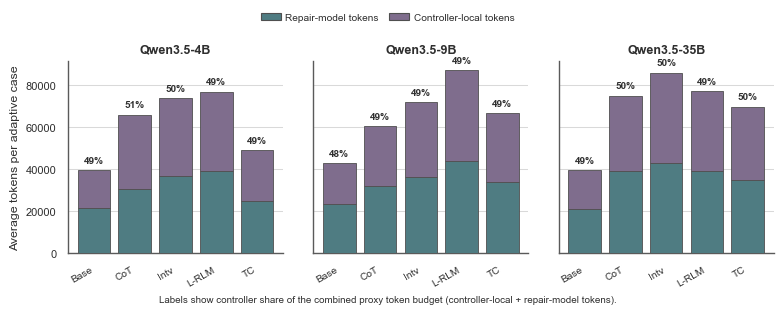

'analysis/figures/policy_controller_overhead_decomposition.pdf'

In [16]:
try:
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy and matplotlib. Install them in the notebook kernel, "
        "for example with `uv pip install numpy matplotlib`."
    ) from exc

required_names = [
    "policy_overhead_summary",
    "POLICY_MODEL_ORDER",
    "POLICY_MODEL_DISPLAY",
    "BASELINE_ORDER",
    "BASELINE_SHORT_DISPLAY",
    "apply_figure_style",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the policy diagnostics prep cell first. Missing names: " + ", ".join(missing_names)
    )

bar_style = apply_figure_style("bars")
component_colors = bar_style["overhead_colors"]
max_total = float(policy_overhead_summary["mean_combined_tokens"].max())

fig, axes = plt.subplots(
    1,
    3,
    figsize=(7.8, 3.0),
    sharey=True,
)
for ax, model_size in zip(axes, POLICY_MODEL_ORDER):
    subset = policy_overhead_summary.loc[
        policy_overhead_summary["model_size"] == model_size
    ].copy()
    subset["baseline_order"] = subset["baseline"].map({baseline: i for i, baseline in enumerate(BASELINE_ORDER)})
    subset = subset.sort_values("baseline_order")
    x = np.arange(len(BASELINE_ORDER), dtype=float)
    repair_values = subset["mean_repair_model_tokens"].to_numpy(dtype=float)
    controller_values = subset["mean_controller_local_tokens"].to_numpy(dtype=float)
    combined_values = repair_values + controller_values

    ax.bar(
        x,
        repair_values,
        color=component_colors["repair_model"],
        edgecolor=bar_style["bar_edgecolor"],
        linewidth=0.6,
        label="Repair-model tokens",
        zorder=3,
    )
    ax.bar(
        x,
        controller_values,
        bottom=repair_values,
        color=component_colors["controller_local"],
        edgecolor=bar_style["bar_edgecolor"],
        linewidth=0.6,
        label="Controller-local tokens",
        zorder=3,
    )

    for x_pos, total_value, share_value in zip(x, combined_values, subset["mean_controller_share_pct"]):
        ax.text(
            x_pos,
            total_value + max_total * 0.03,
            f"{share_value:.0f}%",
            ha="center",
            va="bottom",
            fontsize=7.2,
            color=bar_style["label_color"],
            weight="bold",
        )

    ax.set_title(POLICY_MODEL_DISPLAY[model_size], fontsize=9.0, weight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(
        [BASELINE_SHORT_DISPLAY[baseline] for baseline in BASELINE_ORDER],
        rotation=30,
        ha="right",
        fontsize=bar_style["xtick_label_fontsize"],
    )
    ax.set_facecolor(bar_style["axes_facecolor"])
    ax.grid(True, axis="y", color=bar_style["grid_color"], linewidth=bar_style["grid_linewidth"])
    ax.grid(False, axis="x")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(bar_style["spine_color"])
    ax.spines["bottom"].set_color(bar_style["spine_color"])
    ax.tick_params(axis="y", labelsize=bar_style["ytick_label_fontsize"])

axes[0].set_ylabel("Average tokens per adaptive case", fontsize=bar_style["label_fontsize"], color=bar_style["label_color"])
fig.legend(
    handles=[
        Patch(facecolor=component_colors["repair_model"], edgecolor=bar_style["bar_edgecolor"], label="Repair-model tokens"),
        Patch(facecolor=component_colors["controller_local"], edgecolor=bar_style["bar_edgecolor"], label="Controller-local tokens"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=bar_style["legend_frameon"],
    fontsize=bar_style["legend_fontsize"],
    columnspacing=1.0,
    handletextpad=0.45,
)
fig.text(
    0.5,
    0.02,
    "Labels show controller share of the combined proxy token budget (controller-local + repair-model tokens).",
    ha="center",
    va="bottom",
    fontsize=7.0,
    color=bar_style["label_color"],
)
fig.subplots_adjust(left=0.09, right=0.995, top=0.83, bottom=0.19, wspace=0.14)

policy_overhead_decomposition_figure_path = save_figure(
    fig,
    "policy_controller_overhead_decomposition.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(policy_overhead_decomposition_figure_path)


## Policy Balance Summary

Quantify how the adaptive policy balances helper usage: the default behavior would invoke the full helper on every adaptive attempt, while the policy reroutes many attempts to lighter evidence actions or skips. The same summary also reports how often the helper LLM asks for more context and how often extra context is actually materialized.


In [17]:
try:
    import pandas as pd
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This policy-summary cell uses pandas. Install it in the notebook kernel, "
        "for example with `uv pip install pandas`."
    ) from exc

try:
    from IPython.display import display
except ModuleNotFoundError:
    def display(obj):
        print(obj)

required_names = [
    "results_datapoints",
    "read_jsonl_records",
    "POLICY_MODEL_ORDER",
    "POLICY_MODEL_DISPLAY",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the registry and policy prep cells first. Missing names: " + ", ".join(missing_names)
    )

HELPER_CONTEXT_MATERIALIZING_ACTIONS_NOTEBOOK = {
    "invoke_helper",
    "frame_only",
    "file_only",
    "search_only",
    "retry_helper_strict_json",
    "snapshot_lite",
    "frame_locals_lite",
    "snapshot_full_lite",
    "compact_then_patch",
}
LIGHTWEIGHT_CONTEXT_ACTIONS_NOTEBOOK = HELPER_CONTEXT_MATERIALIZING_ACTIONS_NOTEBOOK - {
    "invoke_helper",
    "retry_helper_strict_json",
}

policy_balance_rows = []
for datapoint in results_datapoints:
    if not datapoint.adaptive:
        continue
    for row in read_jsonl_records(datapoint.path):
        meta = row.get("attempt_metadata") or {}
        selected_action = str(meta.get("adaptive_helper_action_selected") or "")
        executed_action = str(meta.get("adaptive_helper_action_executed") or "")
        helper_invoked = bool(meta.get("adaptive_helper_invoked"))
        llm_requested_more_context = bool(
            meta.get("adaptive_helper_need_more_context")
            or meta.get("stage_a_need_snapshot")
            or meta.get("stage_a_need_compact_context")
        )
        materialized_context = bool(meta.get("adaptive_helper_materialized_context")) or int(
            meta.get("stage_a_requests_count") or 0
        ) > 0
        policy_balance_rows.append(
            {
                "model_size": datapoint.model_size,
                "selected_action": selected_action,
                "executed_action": executed_action,
                "helper_invoked": helper_invoked,
                "llm_requested_more_context": llm_requested_more_context,
                "materialized_context": materialized_context,
            }
        )

policy_balance_attempts = pd.DataFrame.from_records(policy_balance_rows)
assert not policy_balance_attempts.empty, "No adaptive attempts were available for the policy balance summary."


def _summarize_policy_balance(frame: pd.DataFrame) -> dict[str, object]:
    attempts = len(frame)
    helper_invoked = int(frame["helper_invoked"].sum())
    helper_slice = frame.loc[frame["helper_invoked"]]
    return {
        "Adaptive attempts": attempts,
        "Default full helper": 1.0,
        "Policy-selected full helper": (frame["selected_action"] == "invoke_helper").mean(),
        "Policy-executed full helper": (frame["executed_action"] == "invoke_helper").mean(),
        "Executed lightweight action": frame["executed_action"].isin(
            LIGHTWEIGHT_CONTEXT_ACTIONS_NOTEBOOK
        ).mean(),
        "Executed skip": (frame["executed_action"] == "skip_helper").mean(),
        "LLM asked for more context (all)": frame["llm_requested_more_context"].mean(),
        "LLM asked for more context | helper": helper_slice["llm_requested_more_context"].mean()
        if helper_invoked
        else float("nan"),
        "Context materialized (all)": frame["materialized_context"].mean(),
        "Context materialized | helper": helper_slice["materialized_context"].mean()
        if helper_invoked
        else float("nan"),
    }

policy_balance_summary_rows = []
for model_size in POLICY_MODEL_ORDER:
    subset = policy_balance_attempts.loc[policy_balance_attempts["model_size"] == model_size]
    summary_row = _summarize_policy_balance(subset)
    summary_row["Model"] = POLICY_MODEL_DISPLAY.get(model_size, f"{model_size}B")
    policy_balance_summary_rows.append(summary_row)

overall_summary_row = _summarize_policy_balance(policy_balance_attempts)
overall_summary_row["Model"] = "Overall"
policy_balance_summary_rows.append(overall_summary_row)

policy_tool_balance_summary = pd.DataFrame(policy_balance_summary_rows)[
    [
        "Model",
        "Adaptive attempts",
        "Default full helper",
        "Policy-selected full helper",
        "Policy-executed full helper",
        "Executed lightweight action",
        "Executed skip",
        "LLM asked for more context (all)",
        "LLM asked for more context | helper",
        "Context materialized (all)",
        "Context materialized | helper",
    ]
]

percent_columns = [
    "Default full helper",
    "Policy-selected full helper",
    "Policy-executed full helper",
    "Executed lightweight action",
    "Executed skip",
    "LLM asked for more context (all)",
    "LLM asked for more context | helper",
    "Context materialized (all)",
    "Context materialized | helper",
]
policy_tool_balance_summary_display = policy_tool_balance_summary.copy()
for column in percent_columns:
    policy_tool_balance_summary_display[column] = policy_tool_balance_summary_display[column].map(
        lambda value: f"{value:.1%}" if pd.notna(value) else "-"
    )

display(policy_tool_balance_summary_display)

policy_tool_balance_summary_display


,Model,Adaptive attempts,Default full helper,Policy-selected full helper,Policy-executed full helper,Executed lightweight action,Executed skip,LLM asked for more context (all),LLM asked for more context | helper,Context materialized (all),Context materialized | helper
0,Qwen3.5-4B,8644,100.0%,9.5%,29.8%,53.4%,16.8%,19.0%,44.3%,19.0%,44.3%
1,Qwen3.5-9B,6582,100.0%,9.6%,28.9%,57.1%,13.9%,1.9%,4.6%,1.9%,4.6%
2,Qwen3.5-35B,4918,100.0%,8.1%,26.6%,54.0%,19.4%,27.8%,66.3%,27.8%,66.3%
3,Overall,20144,100.0%,9.2%,28.7%,54.8%,16.5%,15.5%,37.1%,15.5%,37.1%


,Model,Adaptive attempts,Default full helper,Policy-selected full helper,Policy-executed full helper,Executed lightweight action,Executed skip,LLM asked for more context (all),LLM asked for more context | helper,Context materialized (all),Context materialized | helper
0,Qwen3.5-4B,8644,100.0%,9.5%,29.8%,53.4%,16.8%,19.0%,44.3%,19.0%,44.3%
1,Qwen3.5-9B,6582,100.0%,9.6%,28.9%,57.1%,13.9%,1.9%,4.6%,1.9%,4.6%
2,Qwen3.5-35B,4918,100.0%,8.1%,26.6%,54.0%,19.4%,27.8%,66.3%,27.8%,66.3%
3,Overall,20144,100.0%,9.2%,28.7%,54.8%,16.5%,15.5%,37.1%,15.5%,37.1%


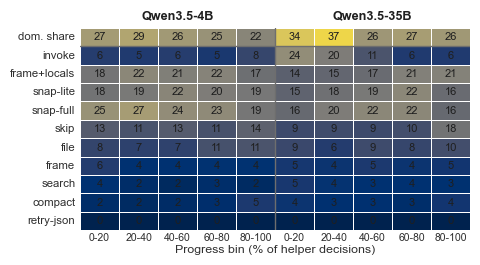

'analysis/figures/policy_helper_development_over_time.pdf'

In [18]:
try:
    import numpy as np
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy, pandas, seaborn, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas seaborn matplotlib`."
    ) from exc

required_names = [
    "helper_policy_events",
    "HELPER_ACTION_ORDER",
    "HELPER_ACTION_DISPLAY",
    "POLICY_MODEL_DISPLAY",
    "REPO_ROOT",
    "apply_figure_style",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the policy analysis prep cell first. Missing names: " + ", ".join(missing_names)
    )

plot_model_sizes = [4, 35]
display_bins = 5
progress_bin_order = list(range(1, display_bins + 1))
progress_bin_labels = [f"{20 * (bin_index - 1)}-{20 * bin_index}" for bin_index in progress_bin_order]

plot_events = helper_policy_events.loc[
    helper_policy_events["model_size"].isin(plot_model_sizes)
].copy()
plot_events["display_bin"] = pd.cut(
    plot_events["progress_frac"],
    bins=np.linspace(0.0, 1.0, display_bins + 1),
    labels=progress_bin_order,
    include_lowest=True,
).astype(int)

per_run_counts = (
    plot_events.groupby(["model_size", "run_id", "display_bin", "selected_action"]).size()
    .unstack(fill_value=0)
    .reindex(columns=HELPER_ACTION_ORDER, fill_value=0)
)
per_run_shares = per_run_counts.div(per_run_counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

mean_action_share = (
    per_run_shares.stack()
    .rename("share")
    .reset_index()
    .groupby(["model_size", "display_bin", "selected_action"], as_index=False)["share"]
    .mean()
)
mean_dominant_share = (
    per_run_shares.max(axis=1)
    .rename("share")
    .reset_index()
    .groupby(["model_size", "display_bin"], as_index=False)["share"]
    .mean()
)

row_order = ["dom_share", *HELPER_ACTION_ORDER]
row_labels = ["dom. share", *[HELPER_ACTION_DISPLAY[action] for action in HELPER_ACTION_ORDER]]
num_columns = display_bins * len(plot_model_sizes)
matrix = np.full((len(row_order), num_columns), np.nan)
annotations = np.full((len(row_order), num_columns), "", dtype=object)

for model_index, model_size in enumerate(plot_model_sizes):
    column_start = model_index * display_bins
    dominant_values = (
        mean_dominant_share.loc[mean_dominant_share["model_size"] == model_size]
        .set_index("display_bin")
        .reindex(progress_bin_order)["share"]
        .to_numpy(dtype=float)
        * 100
    )
    matrix[0, column_start : column_start + display_bins] = dominant_values
    annotations[0, column_start : column_start + display_bins] = [f"{value:.0f}" for value in dominant_values]

    share_table = (
        mean_action_share.loc[mean_action_share["model_size"] == model_size]
        .pivot(index="selected_action", columns="display_bin", values="share")
        .reindex(index=HELPER_ACTION_ORDER, columns=progress_bin_order, fill_value=0.0)
        .to_numpy(dtype=float)
        * 100
    )
    matrix[1:, column_start : column_start + display_bins] = share_table
    for row_index in range(share_table.shape[0]):
        annotations[row_index + 1, column_start : column_start + display_bins] = [
            f"{value:.0f}" for value in share_table[row_index]
        ]

xtick_labels = progress_bin_labels * len(plot_model_sizes)
heatmap_style = apply_figure_style("heatmap")

fig, ax = plt.subplots(figsize=(5.2, 2.85))
sns.heatmap(
    matrix,
    annot=annotations,
    fmt="",
    cmap=heatmap_style["cmap"],
    vmin=0,
    vmax=40,
    linewidths=0.55,
    linecolor=heatmap_style["cell_linecolor"],
    cbar=False,
    annot_kws={
        "fontsize": heatmap_style["annotation_fontsize"],
        "color": heatmap_style["annotation_color"],
    },
    ax=ax,
)
ax.set_xticks(np.arange(num_columns) + 0.5)
ax.set_xticklabels(xtick_labels, rotation=0, fontsize=heatmap_style["xtick_label_fontsize"])
ax.set_yticks(np.arange(len(row_labels)) + 0.5)
ax.set_yticklabels(row_labels, rotation=0, fontsize=heatmap_style["ytick_label_fontsize"])
ax.tick_params(length=0)
ax.tick_params(axis="x", pad=1.5)
ax.set_xlabel("Progress bin (% of helper decisions)", fontsize=heatmap_style["axis_label_fontsize"], labelpad=2)
ax.set_ylabel("")
ax.axhline(1, color=heatmap_style["separator_color"], linewidth=1.0)
ax.axvline(display_bins, color=heatmap_style["separator_color"], linewidth=1.0)
ax.text(
    0.25,
    1.03,
    POLICY_MODEL_DISPLAY[4],
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=heatmap_style["header_fontsize"],
    weight="bold",
    color=heatmap_style["annotation_color"],
)
ax.text(
    0.75,
    1.03,
    POLICY_MODEL_DISPLAY[35],
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=heatmap_style["header_fontsize"],
    weight="bold",
    color=heatmap_style["annotation_color"],
)
fig.subplots_adjust(top=0.87, left=0.24, right=0.99, bottom=0.16)

policy_action_development_figure_path = save_figure(
    fig,
    "policy_helper_development_over_time.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(policy_action_development_figure_path)


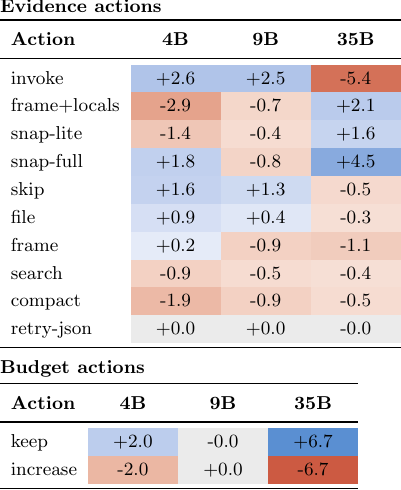

{'pdf': 'analysis/figures/policy_action_enrichment_table.pdf',
 'preview': 'analysis/figures/policy_action_enrichment_table.png'}

In [19]:
try:
    import pandas as pd
    from IPython.display import Image, display
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses pandas and IPython display utilities. "
        "Install pandas in the notebook kernel, for example with `uv pip install pandas`."
    ) from exc

import shutil
import subprocess

required_names = [
    "helper_action_summary",
    "budget_action_summary",
    "HELPER_ACTION_ORDER",
    "HELPER_ACTION_DISPLAY",
    "BUDGET_ACTION_ORDER",
    "BUDGET_ACTION_DISPLAY",
    "POLICY_MODEL_ORDER",
    "REPO_ROOT",
    "figure_output_path",
    "FIGURE_LATEX_BORDER_PT",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the policy analysis prep cell first. Missing names: " + ", ".join(missing_names)
    )

if shutil.which("pdflatex") is None:
    raise RuntimeError("pdflatex is required for the LaTeX-rendered enrichment table.")

tex_path = figure_output_path("policy_action_enrichment_table.tex", export_format="tex")
figure_dir = tex_path.parent
figure_dir.mkdir(parents=True, exist_ok=True)
pdf_path = figure_output_path("policy_action_enrichment_table.pdf", export_format="pdf")
png_path = figure_output_path("policy_action_enrichment_table.png", export_format="png")
png_prefix = png_path.with_suffix("")

model_order = [4, 9, 35]

helper_matrix = (
    helper_action_summary.pivot(index="selected_action", columns="model_size", values="enrichment_pp")
    .reindex(index=HELPER_ACTION_ORDER, columns=model_order)
)
budget_matrix = (
    budget_action_summary.pivot(index="selected_action", columns="model_size", values="enrichment_pp")
    .reindex(index=BUDGET_ACTION_ORDER, columns=model_order)
)

non_missing_values = [
    float(value)
    for value in list(helper_matrix.to_numpy().ravel()) + list(budget_matrix.to_numpy().ravel())
    if pd.notna(value)
]
max_abs_value = max(non_missing_values) if non_missing_values else 1.0


def color_intensity(value: float) -> int:
    scaled = 8 + 60 * abs(value) / max_abs_value
    return max(8, min(70, int(round(scaled))))


def latex_cell(value: float | None) -> str:
    if value is None or pd.isna(value):
        return r"\cellcolor{black!8}\textit{n/a}"
    if abs(float(value)) < 0.05:
        background = "black!8"
    elif float(value) > 0:
        background = f"RoyalBlue!{color_intensity(float(value))}"
    else:
        background = f"BrickRed!{color_intensity(float(value))}"
    return rf"\cellcolor{{{background}}}{float(value):+.1f}"


helper_rows_tex = "\n".join(
    f"{HELPER_ACTION_DISPLAY[action]} & "
    + " & ".join(latex_cell(helper_matrix.loc[action, model_size]) for model_size in model_order)
    + r" \\" 
    for action in HELPER_ACTION_ORDER
)
budget_rows_tex = "\n".join(
    f"{BUDGET_ACTION_DISPLAY[action]} & "
    + " & ".join(latex_cell(budget_matrix.loc[action, model_size]) for model_size in model_order)
    + r" \\" 
    for action in BUDGET_ACTION_ORDER
)

tex_source = r"""
\documentclass[varwidth,border=__STANDALONE_BORDER__pt]{standalone}
\usepackage[table,dvipsnames]{xcolor}
\usepackage{array,booktabs}
\begin{document}
{\small
\renewcommand{\arraystretch}{1.22}
\setlength{\tabcolsep}{5.2pt}
\textbf{Evidence actions}\\[0.2em]
\begin{tabular}{l>{\centering\arraybackslash}m{1.16cm}>{\centering\arraybackslash}m{1.16cm}>{\centering\arraybackslash}m{1.16cm}}
\toprule
\textbf{Action} & \textbf{4B} & \textbf{9B} & \textbf{35B} \\
\midrule
__HELPER_ROWS__
\bottomrule
\end{tabular}\\[0.5em]
\textbf{Budget actions}\\[0.2em]
\begin{tabular}{l>{\centering\arraybackslash}m{1.16cm}>{\centering\arraybackslash}m{1.16cm}>{\centering\arraybackslash}m{1.16cm}}
\toprule
\textbf{Action} & \textbf{4B} & \textbf{9B} & \textbf{35B} \\
\midrule
__BUDGET_ROWS__
\bottomrule
\end{tabular}
}
\end{document}
"""
tex_source = (
    tex_source.replace("__HELPER_ROWS__", helper_rows_tex)
    .replace("__BUDGET_ROWS__", budget_rows_tex)
    .replace("__STANDALONE_BORDER__", str(FIGURE_LATEX_BORDER_PT))
)
tex_path.write_text(tex_source, encoding="utf-8")

compile_proc = subprocess.run(
    [
        "pdflatex",
        "-interaction=nonstopmode",
        "-halt-on-error",
        f"-output-directory={figure_dir}",
        str(tex_path),
    ],
    capture_output=True,
    text=True,
)
if compile_proc.returncode != 0:
    raise RuntimeError(
        "pdflatex failed while compiling the enrichment table:\n"
        + compile_proc.stdout[-4000:]
        + "\n"
        + compile_proc.stderr[-4000:]
    )

for suffix in [".aux", ".log"]:
    aux_path = figure_dir / f"{tex_path.stem}{suffix}"
    if aux_path.exists():
        aux_path.unlink()

if shutil.which("pdftoppm") is not None:
    subprocess.run(
        ["pdftoppm", "-png", "-singlefile", str(pdf_path), str(png_prefix)],
        check=True,
        capture_output=True,
        text=True,
    )

if png_path.exists():
    display(Image(filename=str(png_path)))

policy_action_enrichment_figure_path = pdf_path
policy_action_enrichment_preview_path = png_path if png_path.exists() else None
repo_relative_paths({
    "pdf": policy_action_enrichment_figure_path,
    "preview": policy_action_enrichment_preview_path,
})



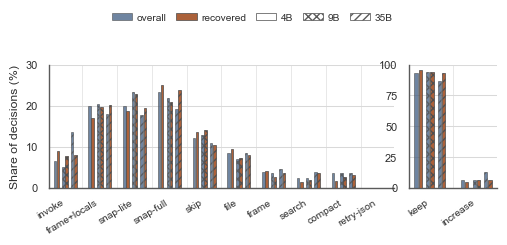

'analysis/figures/policy_action_mix_grouped_bars.pdf'

In [20]:
try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy, pandas, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas matplotlib`."
    ) from exc

required_names = [
    "helper_action_summary",
    "budget_action_summary",
    "HELPER_ACTION_ORDER",
    "HELPER_ACTION_DISPLAY",
    "BUDGET_ACTION_ORDER",
    "BUDGET_ACTION_DISPLAY",
    "REPO_ROOT",
    "apply_figure_style",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the policy analysis prep cell first. Missing names: " + ", ".join(missing_names)
    )

bar_style = apply_figure_style("bars")
plot_model_sizes = [4, 9, 35]
model_hatch = bar_style["model_hatch"]
placeholder_face = bar_style["placeholder_face"]
bar_width = 0.060
action_gap = 0.84
pair_offsets = {4: -0.21, 9: 0.0, 35: 0.21}
state_offsets = {"overall_share_pct": -0.038, "recovered_share_pct": 0.038}
state_colors = bar_style["state_colors"]
state_alpha = bar_style["state_alpha"]
placeholder_height = {"evidence": 0.85, "budget": 2.2}


def draw_grouped_panel(ax, summary_df, action_order, action_display, *, panel_kind, ylim, yticks, rotation):
    base_positions = np.arange(len(action_order), dtype=float) * action_gap
    summary_lookup = (
        summary_df.set_index(["model_size", "selected_action"])
        [["overall_share_pct", "recovered_share_pct"]]
        .sort_index()
    )

    for boundary in base_positions[:-1] + action_gap / 2:
        ax.axvline(boundary, color=bar_style["boundary_color"], linewidth=0.7, zorder=0)

    for model_size in plot_model_sizes:
        pair_centers = base_positions + pair_offsets[model_size]
        for state_name in ["overall_share_pct", "recovered_share_pct"]:
            values = []
            for action in action_order:
                value = summary_lookup.loc[(model_size, action), state_name]
                if pd.isna(value):
                    values.append(np.nan)
                else:
                    values.append(float(value))

            plot_positions = pair_centers + state_offsets[state_name]
            has_data = np.array([pd.notna(value) for value in values], dtype=bool)
            if has_data.any():
                ax.bar(
                    plot_positions[has_data],
                    np.array(values, dtype=float)[has_data],
                    width=bar_width,
                    color=state_colors[state_name],
                    alpha=state_alpha[state_name],
                    edgecolor=bar_style["bar_edgecolor"],
                    linewidth=0.55,
                    hatch=model_hatch[model_size],
                    zorder=3,
                )
            if (~has_data).any():
                ax.bar(
                    plot_positions[~has_data],
                    np.full((~has_data).sum(), placeholder_height[panel_kind]),
                    width=bar_width,
                    color=placeholder_face,
                    alpha=1.0,
                    edgecolor=bar_style["placeholder_edgecolor"],
                    linewidth=0.55,
                    hatch=model_hatch[model_size],
                    zorder=2,
                )

    ax.set_facecolor(bar_style["axes_facecolor"])
    ax.set_xlim(base_positions[0] - 0.38, base_positions[-1] + 0.38)
    ax.set_ylim(0, ylim)
    ax.set_yticks(yticks)
    ax.set_xticks(base_positions)
    ax.set_xticklabels(
        [action_display[action] for action in action_order],
        rotation=rotation,
        ha="right",
        fontsize=bar_style["xtick_label_fontsize"],
    )
    ax.tick_params(axis="x", which="major", pad=7, length=0, colors=bar_style["tick_color"])
    ax.tick_params(axis="y", labelsize=bar_style["ytick_label_fontsize"], colors=bar_style["tick_color"])
    ax.grid(True, axis="y", color=bar_style["grid_color"], linewidth=bar_style["grid_linewidth"])
    ax.grid(False, axis="x")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(bar_style["spine_color"])
    ax.spines["bottom"].set_color(bar_style["spine_color"])


fig, (ax_evidence, ax_budget) = plt.subplots(
    1,
    2,
    figsize=(4.95, 2.28),
    gridspec_kw={"width_ratios": [5.25, 1.35], "wspace": 0.07},
)

draw_grouped_panel(
    ax_evidence,
    helper_action_summary,
    HELPER_ACTION_ORDER,
    HELPER_ACTION_DISPLAY,
    panel_kind="evidence",
    ylim=30,
    yticks=[0, 10, 20, 30],
    rotation=31,
)
draw_grouped_panel(
    ax_budget,
    budget_action_summary,
    BUDGET_ACTION_ORDER,
    BUDGET_ACTION_DISPLAY,
    panel_kind="budget",
    ylim=100,
    yticks=[0, 25, 50, 75, 100],
    rotation=36,
)

ax_evidence.set_ylabel(
    "Share of decisions (%)",
    fontsize=bar_style["label_fontsize"],
    color=bar_style["label_color"],
)
ax_budget.set_ylabel("")

legend_handles = [
    Patch(
        facecolor=state_colors["overall_share_pct"],
        edgecolor=bar_style["bar_edgecolor"],
        linewidth=0.55,
        alpha=state_alpha["overall_share_pct"],
        label="overall",
    ),
    Patch(
        facecolor=state_colors["recovered_share_pct"],
        edgecolor=bar_style["bar_edgecolor"],
        linewidth=0.55,
        alpha=state_alpha["recovered_share_pct"],
        label="recovered",
    ),
    Patch(
        facecolor=bar_style["legend_blank_facecolor"],
        edgecolor=bar_style["spine_color"],
        linewidth=0.55,
        hatch=model_hatch[4],
        label="4B",
    ),
    Patch(
        facecolor=bar_style["legend_blank_facecolor"],
        edgecolor=bar_style["spine_color"],
        linewidth=0.55,
        hatch=model_hatch[9],
        label="9B",
    ),
    Patch(
        facecolor=bar_style["legend_blank_facecolor"],
        edgecolor=bar_style["spine_color"],
        linewidth=0.55,
        hatch=model_hatch[35],
        label="35B",
    ),
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=bar_style["legend_frameon"],
    fontsize=bar_style["legend_fontsize"],
    handletextpad=0.45,
    columnspacing=0.95,
)
fig.subplots_adjust(top=0.73, left=0.09, right=0.995, bottom=0.19)

policy_action_mix_bar_figure_path = save_figure(
    fig,
    "policy_action_mix_grouped_bars.png",
    dpi=300,
)
show_figure(fig)
repo_relative_path(policy_action_mix_bar_figure_path)


### Policy Action Mix Alternatives

These variants keep model sizes directly comparable within each action while making the bars thicker and easier to read in paper layouts.


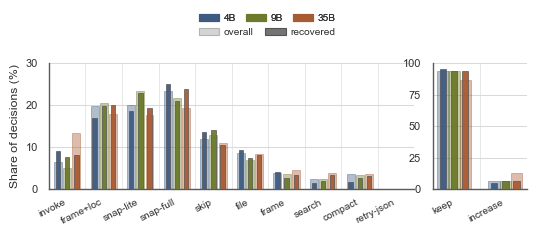

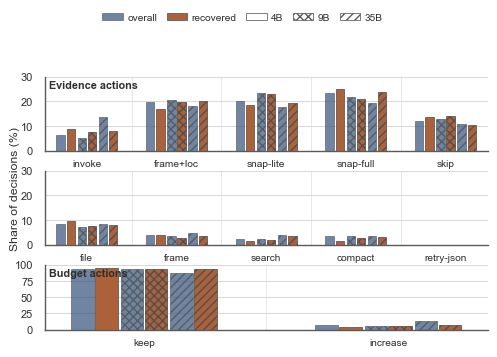

{'overlay_by_model': 'analysis/figures/policy_action_mix_overlay_by_model.pdf',
 'split_rows_grouped': 'analysis/figures/policy_action_mix_grouped_bars_split_rows.pdf'}

In [21]:
try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "This figure cell uses numpy, pandas, and matplotlib. "
        "Install them in the notebook kernel, for example with `uv pip install numpy pandas matplotlib`."
    ) from exc

required_names = [
    "helper_action_summary",
    "budget_action_summary",
    "HELPER_ACTION_ORDER",
    "HELPER_ACTION_DISPLAY",
    "BUDGET_ACTION_ORDER",
    "BUDGET_ACTION_DISPLAY",
    "POLICY_MODEL_ORDER",
    "apply_figure_style",
    "save_figure",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the policy analysis prep cell first. Missing names: " + ", ".join(missing_names)
    )

bar_style = apply_figure_style("bars")
plot_model_sizes = POLICY_MODEL_ORDER
state_colors = bar_style["state_colors"]
state_alpha = bar_style["state_alpha"]
model_hatch = bar_style["model_hatch"]
model_color_map = PAPER_MODEL_COLORS
model_label_map = {4: "4B", 9: "9B", 35: "35B"}
helper_action_display_compact = {
    **HELPER_ACTION_DISPLAY,
    "frame_locals_lite": "frame+loc",
    "retry_helper_strict_json": "retry-json",
}


def style_policy_axis(ax, *, ylim, yticks):
    ax.set_facecolor(bar_style["axes_facecolor"])
    ax.set_ylim(0, ylim)
    ax.set_yticks(yticks)
    ax.tick_params(axis="y", labelsize=bar_style["ytick_label_fontsize"], colors=bar_style["tick_color"])
    ax.tick_params(axis="x", which="major", pad=6, length=0, colors=bar_style["tick_color"])
    ax.grid(True, axis="y", color=bar_style["grid_color"], linewidth=bar_style["grid_linewidth"])
    ax.grid(False, axis="x")
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(bar_style["spine_color"])
    ax.spines["bottom"].set_color(bar_style["spine_color"])


def summary_lookup(summary_df):
    return (
        summary_df.set_index(["model_size", "selected_action"])
        [["overall_share_pct", "recovered_share_pct"]]
        .sort_index()
    )


def draw_overlay_panel(ax, summary_df, action_order, action_display, *, ylim, yticks, rotation, gap, model_offsets, outer_width, inner_width):
    lookup = summary_lookup(summary_df)
    base_positions = np.arange(len(action_order), dtype=float) * gap
    for boundary in base_positions[:-1] + gap / 2:
        ax.axvline(boundary, color=bar_style["boundary_color"], linewidth=0.7, zorder=0)

    for model_size in plot_model_sizes:
        positions = base_positions + model_offsets[model_size]
        overall_values = np.array(
            [float(lookup.loc[(model_size, action), "overall_share_pct"]) for action in action_order],
            dtype=float,
        )
        recovered_values = np.array(
            [float(lookup.loc[(model_size, action), "recovered_share_pct"]) for action in action_order],
            dtype=float,
        )
        ax.bar(
            positions,
            overall_values,
            width=outer_width,
            color=model_color_map[model_size],
            alpha=0.40,
            edgecolor=model_color_map[model_size],
            linewidth=0.7,
            zorder=2,
        )
        ax.bar(
            positions,
            recovered_values,
            width=inner_width,
            color=model_color_map[model_size],
            alpha=0.94,
            edgecolor="#4F4F4F",
            linewidth=0.5,
            zorder=3,
        )

    style_policy_axis(ax, ylim=ylim, yticks=yticks)
    ax.set_xlim(base_positions[0] - 0.45, base_positions[-1] + 0.45)
    ax.set_xticks(base_positions)
    ax.set_xticklabels(
        [action_display[action] for action in action_order],
        rotation=rotation,
        ha="right" if rotation else "center",
        fontsize=bar_style["xtick_label_fontsize"],
    )


def draw_grouped_split_panel(ax, summary_df, action_order, action_display, *, ylim, yticks, rotation, gap, pair_offsets, state_offsets, bar_width):
    lookup = summary_lookup(summary_df)
    base_positions = np.arange(len(action_order), dtype=float) * gap
    for boundary in base_positions[:-1] + gap / 2:
        ax.axvline(boundary, color=bar_style["boundary_color"], linewidth=0.7, zorder=0)

    for model_size in plot_model_sizes:
        pair_centers = base_positions + pair_offsets[model_size]
        for state_name in ["overall_share_pct", "recovered_share_pct"]:
            values = np.array(
                [float(lookup.loc[(model_size, action), state_name]) for action in action_order],
                dtype=float,
            )
            ax.bar(
                pair_centers + state_offsets[state_name],
                values,
                width=bar_width,
                color=state_colors[state_name],
                alpha=state_alpha[state_name],
                edgecolor=bar_style["bar_edgecolor"],
                linewidth=0.55,
                hatch=model_hatch[model_size],
                zorder=3,
            )

    style_policy_axis(ax, ylim=ylim, yticks=yticks)
    ax.set_xlim(base_positions[0] - 0.48, base_positions[-1] + 0.48)
    ax.set_xticks(base_positions)
    ax.set_xticklabels(
        [action_display[action] for action in action_order],
        rotation=rotation,
        ha="right" if rotation else "center",
        fontsize=bar_style["xtick_label_fontsize"],
    )


# Variant 1: model-size-colored bars with recovered overlays inside each bar.
overlay_gap = 0.92
overlay_offsets = {4: -0.23, 9: 0.0, 35: 0.23}
fig_overlay, (ax_overlay_evidence, ax_overlay_budget) = plt.subplots(
    1,
    2,
    figsize=(5.25, 2.38),
    gridspec_kw={"width_ratios": [5.4, 1.4], "wspace": 0.08},
)
draw_overlay_panel(
    ax_overlay_evidence,
    helper_action_summary,
    HELPER_ACTION_ORDER,
    helper_action_display_compact,
    ylim=30,
    yticks=[0, 10, 20, 30],
    rotation=27,
    gap=overlay_gap,
    model_offsets=overlay_offsets,
    outer_width=0.20,
    inner_width=0.11,
)
draw_overlay_panel(
    ax_overlay_budget,
    budget_action_summary,
    BUDGET_ACTION_ORDER,
    BUDGET_ACTION_DISPLAY,
    ylim=100,
    yticks=[0, 25, 50, 75, 100],
    rotation=28,
    gap=1.06,
    model_offsets=overlay_offsets,
    outer_width=0.24,
    inner_width=0.13,
)
ax_overlay_evidence.set_ylabel(
    "Share of decisions (%)",
    fontsize=bar_style["label_fontsize"],
    color=bar_style["label_color"],
)
ax_overlay_budget.set_ylabel("")
model_legend_handles = [
    Patch(
        facecolor=model_color_map[model_size],
        edgecolor=model_color_map[model_size],
        label=model_label_map[model_size],
    )
    for model_size in plot_model_sizes
]
state_legend_handles = [
    Patch(facecolor="#B8B8B8", edgecolor="#8A8A8A", alpha=0.58, label="overall"),
    Patch(facecolor="#6E6E6E", edgecolor="#4F4F4F", alpha=0.96, label="recovered"),
]
model_legend = fig_overlay.legend(
    handles=model_legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=3,
    frameon=bar_style["legend_frameon"],
    fontsize=bar_style["legend_fontsize"],
    handletextpad=0.45,
    columnspacing=0.95,
)
fig_overlay.add_artist(model_legend)
fig_overlay.legend(
    handles=state_legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.935),
    ncol=2,
    frameon=bar_style["legend_frameon"],
    fontsize=bar_style["legend_fontsize"],
    handletextpad=0.45,
    columnspacing=1.15,
)
fig_overlay.subplots_adjust(top=0.75, left=0.085, right=0.995, bottom=0.22)
policy_action_mix_overlay_figure_path = save_figure(
    fig_overlay,
    "policy_action_mix_overlay_by_model.png",
    dpi=300,
)
show_figure(fig_overlay)


# Variant 2: keep grouped semantics but split evidence actions across two rows.
helper_action_rows = [
    HELPER_ACTION_ORDER[:5],
    HELPER_ACTION_ORDER[5:],
]
split_pair_offsets = {4: -0.24, 9: 0.0, 35: 0.24}
split_state_offsets = {"overall_share_pct": -0.058, "recovered_share_pct": 0.058}
fig_split, axes_split = plt.subplots(
    3,
    1,
    figsize=(4.95, 3.72),
    gridspec_kw={"height_ratios": [1.0, 1.0, 0.88], "hspace": 0.28},
)
draw_grouped_split_panel(
    axes_split[0],
    helper_action_summary,
    helper_action_rows[0],
    helper_action_display_compact,
    ylim=30,
    yticks=[0, 10, 20, 30],
    rotation=0,
    gap=1.02,
    pair_offsets=split_pair_offsets,
    state_offsets=split_state_offsets,
    bar_width=0.095,
)
draw_grouped_split_panel(
    axes_split[1],
    helper_action_summary,
    helper_action_rows[1],
    helper_action_display_compact,
    ylim=30,
    yticks=[0, 10, 20, 30],
    rotation=0,
    gap=1.02,
    pair_offsets=split_pair_offsets,
    state_offsets=split_state_offsets,
    bar_width=0.095,
)
draw_grouped_split_panel(
    axes_split[2],
    budget_action_summary,
    BUDGET_ACTION_ORDER,
    BUDGET_ACTION_DISPLAY,
    ylim=100,
    yticks=[0, 25, 50, 75, 100],
    rotation=0,
    gap=1.18,
    pair_offsets=split_pair_offsets,
    state_offsets=split_state_offsets,
    bar_width=0.11,
)
fig_split.supylabel(
    "Share of decisions (%)",
    fontsize=bar_style["label_fontsize"],
    color=bar_style["label_color"],
    x=0.03,
)
axes_split[0].text(0.01, 0.95, "Evidence actions", transform=axes_split[0].transAxes, ha="left", va="top", fontsize=7.8, color=bar_style["label_color"], weight="bold")
axes_split[2].text(0.01, 0.95, "Budget actions", transform=axes_split[2].transAxes, ha="left", va="top", fontsize=7.8, color=bar_style["label_color"], weight="bold")
fig_split.legend(
    handles=[
        Patch(
            facecolor=state_colors["overall_share_pct"],
            edgecolor=bar_style["bar_edgecolor"],
            linewidth=0.55,
            alpha=state_alpha["overall_share_pct"],
            label="overall",
        ),
        Patch(
            facecolor=state_colors["recovered_share_pct"],
            edgecolor=bar_style["bar_edgecolor"],
            linewidth=0.55,
            alpha=state_alpha["recovered_share_pct"],
            label="recovered",
        ),
        Patch(
            facecolor=bar_style["legend_blank_facecolor"],
            edgecolor=bar_style["spine_color"],
            linewidth=0.55,
            hatch=model_hatch[4],
            label="4B",
        ),
        Patch(
            facecolor=bar_style["legend_blank_facecolor"],
            edgecolor=bar_style["spine_color"],
            linewidth=0.55,
            hatch=model_hatch[9],
            label="9B",
        ),
        Patch(
            facecolor=bar_style["legend_blank_facecolor"],
            edgecolor=bar_style["spine_color"],
            linewidth=0.55,
            hatch=model_hatch[35],
            label="35B",
        ),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=bar_style["legend_frameon"],
    fontsize=bar_style["legend_fontsize"],
    handletextpad=0.45,
    columnspacing=0.95,
)
fig_split.subplots_adjust(top=0.80, left=0.10, right=0.995, bottom=0.12)
policy_action_mix_splitrow_figure_path = save_figure(
    fig_split,
    "policy_action_mix_grouped_bars_split_rows.png",
    dpi=300,
)
show_figure(fig_split)

policy_action_mix_variant_paths = {
    "overlay_by_model": policy_action_mix_overlay_figure_path,
    "split_rows_grouped": policy_action_mix_splitrow_figure_path,
}
repo_relative_paths(policy_action_mix_variant_paths)
